# EMCRAG R1 — Valutazione RAGAS e preparazione del confronto R0→R1

Questo notebook valuta esclusivamente gli output R1 già generati. Non esegue nuovamente R0 e non richiama la pipeline EMCRAG.

La configurazione replica quella utilizzata per R0:

- RAGAS 0.2.5;
- judge GPT-4o;
- embeddings `text-embedding-3-small`;
- Context Precision;
- Context Recall;
- Faithfulness;
- Response Relevancy;
- Noise Sensitivity.

Ogni metrica viene salvata immediatamente in formato JSONL. L’esecuzione è riprendibile e non imputa valori pari a zero alle metriche mancanti o fallite.

In [1]:
# Cella 1 — Preparazione e gate degli input
from pathlib import Path
from collections import Counter
import hashlib
import json
import math
import os
import sys

import pandas as pd
import ragas

PROJECT_DIR = Path("/home/eugrug/Project_CRAG_MedGemma")

MANIFEST_PATH = (
    PROJECT_DIR
    / "benchmark_m0_m1"
    / "inputs_196"
    / "EMCRAG_manifest_196.jsonl"
)

R1_OUTPUT_PATH = (
    PROJECT_DIR
    / "benchmark_r0_r1"
    / "r1_v07_04"
    / "R1_outputs_196.jsonl"
)

R0_DIR = (
    PROJECT_DIR
    / "ragas_results"
    / "ragas_v0611_20260719T010434Z"
)

R0_SCORES_PATH = R0_DIR / "ragas_scores_per_record.csv"

R1_RAGAS_DIR = (
    PROJECT_DIR
    / "benchmark_r0_r1"
    / "ragas_r1_v07_05"
)

R1_CANONICAL_PATH = R1_RAGAS_DIR / "R1_ragas_canonical_inputs.jsonl"
R1_SCORES_PATH = R1_RAGAS_DIR / "R1_ragas_scores.jsonl"
R1_FAILURES_PATH = R1_RAGAS_DIR / "R1_ragas_failures.jsonl"

EXPECTED_RECORDS = 196
EXPECTED_MANIFEST_SHA256 = (
    "51fe2c0d201bf00a9bbed368195009d4ad72edbe740f146179cf04694389c1b5"
)

JUDGE_MODEL = "gpt-4o"
EMBEDDING_MODEL = "text-embedding-3-small"
RAGAS_VERSION = "0.2.5"

R1_RAGAS_DIR.mkdir(parents=True, exist_ok=True)


def require(condition, message):
    if not condition:
        raise RuntimeError(message)


def sha_file(path):
    digest = hashlib.sha256()

    with Path(path).open("rb") as file_handle:
        for block in iter(lambda: file_handle.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()


def read_jsonl(path):
    path = Path(path)

    require(path.is_file(), f"File assente: {path}")

    return [
        json.loads(line)
        for line in path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]


require(MANIFEST_PATH.is_file(), f"Manifest assente: {MANIFEST_PATH}")
require(R1_OUTPUT_PATH.is_file(), f"Output R1 assente: {R1_OUTPUT_PATH}")
require(R0_SCORES_PATH.is_file(), f"Score R0 assenti: {R0_SCORES_PATH}")

require(
    sha_file(MANIFEST_PATH) == EXPECTED_MANIFEST_SHA256,
    "Checksum del manifest diverso: STOP",
)

require(
    ragas.__version__ == RAGAS_VERSION,
    f"Versione RAGAS inattesa: {ragas.__version__}",
)

manifest_rows = read_jsonl(MANIFEST_PATH)
r1_rows = read_jsonl(R1_OUTPUT_PATH)
r0_scores = pd.read_csv(R0_SCORES_PATH)

require(len(manifest_rows) == EXPECTED_RECORDS, "Manifest non composto da 196 record")
require(len(r1_rows) == EXPECTED_RECORDS, "Output R1 non composto da 196 record")
require(r0_scores["sample_id"].nunique() == EXPECTED_RECORDS, "R0 non contiene 196 ID")

manifest_ids = [row["sample_id"] for row in manifest_rows]
r0_ids = r0_scores["sample_id"].astype(str).tolist()
r1_ids = [row["sample_id"] for row in r1_rows]

require(len(set(manifest_ids)) == EXPECTED_RECORDS, "ID duplicati nel manifest")
require(len(set(r1_ids)) == EXPECTED_RECORDS, "ID duplicati negli output R1")
require(set(manifest_ids) == set(r0_ids), "Manifest e R0 non coincidono")
require(set(manifest_ids) == set(r1_ids), "Manifest e R1 non coincidono")

manifest_by_id = {
    row["sample_id"]: row
    for row in manifest_rows
}

r1_by_id = {
    row["sample_id"]: row
    for row in r1_rows
}

canonical_records = []
excluded_records = []

for benchmark_order, sample_id in enumerate(manifest_ids):
    manifest_row = manifest_by_id[sample_id]
    r1_row = r1_by_id[sample_id]

    question = str(
        r1_row.get("question")
        or manifest_row.get("question")
        or ""
    ).strip()

    reference = str(
        r1_row.get("reference_answer")
        or r1_row.get("reference")
        or manifest_row.get("reference_answer")
        or manifest_row.get("reference")
        or ""
    ).strip()

    response = str(
        r1_row.get("answer_for_ragas")
        or r1_row.get("generated_response_before_cleaning")
        or ""
    ).strip()

    local_contexts = r1_row.get("local_contexts") or []

    if isinstance(local_contexts, str):
        local_contexts = [local_contexts]

    local_contexts = [
        str(context).strip()
        for context in local_contexts
        if str(context).strip()
    ]

    web_context = str(
        r1_row.get("web_context") or ""
    ).strip()

    retrieved_contexts = list(local_contexts)

    if web_context:
        retrieved_contexts.append(web_context)

    exclusion_reasons = []

    if not question:
        exclusion_reasons.append("missing_question")

    if not reference:
        exclusion_reasons.append("missing_reference")

    if not response:
        exclusion_reasons.append("missing_response")

    if not retrieved_contexts:
        exclusion_reasons.append("missing_retrieved_contexts")

    if r1_row.get("ragas_eligible") is False:
        exclusion_reasons.append("ragas_ineligible")

    if exclusion_reasons:
        excluded_records.append({
            "sample_id": sample_id,
            "reasons": exclusion_reasons,
        })
        continue

    execution_mode = str(
        r1_row.get("execution_mode")
        or manifest_row.get("execution_mode")
        or (
            "multimodal"
            if manifest_row.get("image_required")
            else "text_only"
        )
    )

    canonical_records.append({
        "sample_id": sample_id,
        "benchmark_order": benchmark_order,
        "dataset": manifest_row["dataset"],
        "execution_mode": execution_mode,
        "image_used": execution_mode == "multimodal",
        "user_input": question,
        "response": response,
        "retrieved_contexts": retrieved_contexts,
        "reference": reference,
    })


with R1_CANONICAL_PATH.open("w", encoding="utf-8") as file_handle:
    for record in canonical_records:
        file_handle.write(
            json.dumps(record, ensure_ascii=False, sort_keys=True) + "\n"
        )


print("INPUT GATE: PASS")
print("Python:", sys.executable)
print("RAGAS:", ragas.__version__)
print("Manifest:", len(manifest_rows))
print("Output R1:", len(r1_rows))
print("RAGAS eleggibili:", len(canonical_records))
print("Esclusi:", len(excluded_records))
print("Esclusioni:", excluded_records)
print("SHA256 output R1:", sha_file(R1_OUTPUT_PATH))
print("Input canonici:", R1_CANONICAL_PATH)

INPUT GATE: PASS
Python: /home/eugrug/miniforge3/envs/conda_ok_14apr/bin/python
RAGAS: 0.2.5
Manifest: 196
Output R1: 196
RAGAS eleggibili: 194
Esclusi: 2
Esclusioni: [{'sample_id': 'mmmed_it_00100', 'reasons': ['ragas_ineligible']}, {'sample_id': 'mmmed_it_00166', 'reasons': ['ragas_ineligible']}]
SHA256 output R1: 686a8629de90e29562d2f45206a34a4e5b6782fd02369258d3a3b586eb878cd0
Input canonici: /home/eugrug/Project_CRAG_MedGemma/benchmark_r0_r1/ragas_r1_v07_05/R1_ragas_canonical_inputs.jsonl


## Configurazione RAGAS

Il judge e le metriche sono mantenuti uguali a R0. Il limite di output del judge è impostato a 4096 token per evitare interruzioni `LLMDidNotFinishException`; questa impostazione non modifica gli input né le risposte R1.

Il runner valuta e salva separatamente ogni combinazione record–metrica. In caso di interruzione può essere rilanciato senza ripetere gli score già disponibili.

In [5]:
#
# Cella 2 — Configurazione API e metriche
#

import time

from langchain_openai import ChatOpenAI, OpenAIEmbeddings

from ragas import evaluate, EvaluationDataset
from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper

from ragas.metrics import (
    LLMContextPrecisionWithReference,
    LLMContextRecall,
    Faithfulness,
    ResponseRelevancy,
    NoiseSensitivity,
)

require(
    bool(os.getenv("OPENAI_API_KEY")),
    "OPENAI_API_KEY assente",
)

judge_llm = ChatOpenAI(
    model=JUDGE_MODEL,
    temperature=0,
    max_tokens=4096,
    max_retries=2,
    request_timeout=180,
)

embedding_llm = OpenAIEmbeddings(
    model=EMBEDDING_MODEL,
    max_retries=2,
    request_timeout=180,
)

ragas_llm = LangchainLLMWrapper(judge_llm)
ragas_embeddings = LangchainEmbeddingsWrapper(embedding_llm)

METRIC_OBJECTS = {
    "context_precision": LLMContextPrecisionWithReference(),
    "context_recall": LLMContextRecall(),
    "faithfulness": Faithfulness(),
    "response_relevancy": ResponseRelevancy(),
    "noise_sensitivity": NoiseSensitivity(),
}

METRIC_NATIVE_KEYS = {
    "context_precision": (
        "llm_context_precision_with_reference",
        "context_precision",
    ),
    "context_recall": (
        "context_recall",
    ),
    "faithfulness": (
        "faithfulness",
    ),
    "response_relevancy": (
        "answer_relevancy",
        "response_relevancy",
    ),
    "noise_sensitivity": (
    "noise_sensitivity_relevant",
    "noise_sensitivity",
    ),
}

print("RAGAS CONFIGURATION: PASS")
print("Judge:", JUDGE_MODEL)
print("Embeddings:", EMBEDDING_MODEL)
print("Metriche:", list(METRIC_OBJECTS))
print("Output:", R1_SCORES_PATH)

RAGAS CONFIGURATION: PASS
Judge: gpt-4o
Embeddings: text-embedding-3-small
Metriche: ['context_precision', 'context_recall', 'faithfulness', 'response_relevancy', 'noise_sensitivity']
Output: /home/eugrug/Project_CRAG_MedGemma/benchmark_r0_r1/ragas_r1_v07_05/R1_ragas_scores.jsonl


In [3]:
# 
# Cella 3 — Runner RAGAS riprendibile
#
def append_jsonl_durable(path, row):
    path = Path(path)

    with path.open("a", encoding="utf-8") as file_handle:
        file_handle.write(
            json.dumps(row, ensure_ascii=False, sort_keys=True) + "\n"
        )
        file_handle.flush()
        os.fsync(file_handle.fileno())


def load_ragas_outcomes():
    successful = {}
    failed = {}

    if R1_SCORES_PATH.is_file():
        for row in read_jsonl(R1_SCORES_PATH):
            key = (row["sample_id"], row["metric"])
            require(key not in successful, f"Score duplicato: {key}")
            successful[key] = row

    if R1_FAILURES_PATH.is_file():
        for row in read_jsonl(R1_FAILURES_PATH):
            key = (row["sample_id"], row["metric"])
            require(key not in failed, f"Failure duplicata: {key}")
            failed[key] = row

    require(
        not (set(successful) & set(failed)),
        "Una combinazione sample/metric è presente sia tra gli score sia tra le failure",
    )

    return successful, failed


def extract_metric_score(metric_name, score_dictionary):
    for native_key in METRIC_NATIVE_KEYS[metric_name]:
        if native_key in score_dictionary:
            value = float(score_dictionary[native_key])

            require(
                math.isfinite(value),
                f"Score non finito: {score_dictionary}",
            )

            return value, native_key

    raise RuntimeError(
        f"Score {metric_name} non trovato in {score_dictionary}"
    )


def is_fatal_api_error(exception):
    message = str(exception).lower()

    fatal_markers = (
        "insufficient_quota",
        "billing",
        "credit balance",
        "authentication",
        "invalid api key",
        "incorrect api key",
    )

    return any(marker in message for marker in fatal_markers)


def run_r1_ragas(max_new_records=None):
    successful, failed = load_ragas_outcomes()
    accounted = set(successful) | set(failed)

    pending_records = [
        record
        for record in canonical_records
        if any(
            (record["sample_id"], metric_name) not in accounted
            for metric_name in METRIC_OBJECTS
        )
    ]

    if max_new_records is not None:
        pending_records = pending_records[:max_new_records]

    print("Score già salvati:", len(successful))
    print("Failure già documentate:", len(failed))
    print("Record selezionati:", len(pending_records))

    r1_output_sha256 = sha_file(R1_OUTPUT_PATH)

    for record_position, record in enumerate(pending_records, 1):
        sample_id = record["sample_id"]

        native_record = {
            "user_input": record["user_input"],
            "response": record["response"],
            "retrieved_contexts": record["retrieved_contexts"],
            "reference": record["reference"],
        }

        dataset = EvaluationDataset.from_list([native_record])

        for metric_name, metric_object in METRIC_OBJECTS.items():
            key = (sample_id, metric_name)

            if key in accounted:
                continue

            started = time.perf_counter()

            try:
                result = evaluate(
                    dataset=dataset,
                    metrics=[metric_object],
                    llm=ragas_llm,
                    embeddings=ragas_embeddings,
                    raise_exceptions=True,
                    in_ci=False,
                    show_progress=False,
                    batch_size=1,
                )

                require(
                    len(result.scores) == 1,
                    "Numero inatteso di score",
                )

                score, native_key = extract_metric_score(
                    metric_name,
                    result.scores[0],
                )

                elapsed_sec = round(
                    time.perf_counter() - started,
                    3,
                )

                output_row = {
                    "status": "success",
                    "sample_id": sample_id,
                    "benchmark_order": record["benchmark_order"],
                    "dataset": record["dataset"],
                    "execution_mode": record["execution_mode"],
                    "metric": metric_name,
                    "native_metric_key": native_key,
                    "score": score,
                    "elapsed_sec": elapsed_sec,
                    "ragas_version": RAGAS_VERSION,
                    "judge_model": JUDGE_MODEL,
                    "embedding_model": EMBEDDING_MODEL,
                    "r1_output_sha256": r1_output_sha256,
                }

                append_jsonl_durable(
                    R1_SCORES_PATH,
                    output_row,
                )

                successful[key] = output_row
                accounted.add(key)

                print(
                    f"[{record_position}/{len(pending_records)}] "
                    f"{sample_id}/{metric_name}: "
                    f"OK score={score:.6f} | "
                    f"{elapsed_sec:.1f}s | "
                    f"salvati={len(successful)}",
                    flush=True,
                )

            except Exception as exception:
                elapsed_sec = round(
                    time.perf_counter() - started,
                    3,
                )

                failure_row = {
                    "status": "failed",
                    "sample_id": sample_id,
                    "benchmark_order": record["benchmark_order"],
                    "dataset": record["dataset"],
                    "execution_mode": record["execution_mode"],
                    "metric": metric_name,
                    "elapsed_sec": elapsed_sec,
                    "exception_type": type(exception).__name__,
                    "exception": str(exception),
                    "ragas_version": RAGAS_VERSION,
                    "judge_model": JUDGE_MODEL,
                    "embedding_model": EMBEDDING_MODEL,
                    "r1_output_sha256": r1_output_sha256,
                }

                append_jsonl_durable(
                    R1_FAILURES_PATH,
                    failure_row,
                )

                failed[key] = failure_row
                accounted.add(key)

                print(
                    f"[{record_position}/{len(pending_records)}] "
                    f"{sample_id}/{metric_name}: FAILED | "
                    f"{type(exception).__name__}: {exception}",
                    flush=True,
                )

                if is_fatal_api_error(exception):
                    raise RuntimeError(
                        "Errore API o credito insufficiente. "
                        "I risultati già completati sono salvati."
                    ) from exception

    total_expected = len(canonical_records) * len(METRIC_OBJECTS)

    print("\nRAGAS BLOCCO TERMINATO")
    print("Score validi:", len(successful), "/", total_expected)
    print("Failure documentate:", len(failed))
    print(
        "Totale contabilizzato:",
        len(successful) + len(failed),
        "/",
        total_expected,
    )

    return R1_SCORES_PATH

In [7]:
#
# Smoke test via OpenAI Key
#
R1_RAGAS_SMOKE_PATH = run_r1_ragas(max_new_records=1)

print("Smoke test completato:", R1_RAGAS_SMOKE_PATH)

Score già salvati: 4
Failure già documentate: 0
Record selezionati: 1
[1/1] imb_00654/noise_sensitivity: OK score=0.333333 | 30.2s | salvati=5

RAGAS BLOCCO TERMINATO
Score validi: 5 / 970
Failure documentate: 0
Totale contabilizzato: 5 / 970
Smoke test completato: /home/eugrug/Project_CRAG_MedGemma/benchmark_r0_r1/ragas_r1_v07_05/R1_ragas_scores.jsonl


In [9]:
#
# Cella 5 — Benchmark R1 completo
#
R1_RAGAS_FULL_PATH = run_r1_ragas()

print("RAGAS R1 completato:", R1_RAGAS_FULL_PATH)

Score già salvati: 53
Failure già documentate: 1
Record selezionati: 184
[1/184] imb_00692/noise_sensitivity: OK score=0.666667 | 46.2s | salvati=54
[2/184] imb_00758/context_precision: OK score=1.000000 | 6.1s | salvati=55
[2/184] imb_00758/context_recall: OK score=0.500000 | 5.0s | salvati=56
[2/184] imb_00758/faithfulness: OK score=0.444444 | 6.7s | salvati=57
[2/184] imb_00758/response_relevancy: OK score=0.360455 | 7.4s | salvati=58
[2/184] imb_00758/noise_sensitivity: OK score=0.444444 | 35.1s | salvati=59
[3/184] imb_00913/context_precision: OK score=1.000000 | 6.9s | salvati=60
[3/184] imb_00913/context_recall: OK score=0.333333 | 4.1s | salvati=61
[3/184] imb_00913/faithfulness: OK score=0.400000 | 7.7s | salvati=62
[3/184] imb_00913/response_relevancy: OK score=0.648159 | 4.4s | salvati=63
[3/184] imb_00913/noise_sensitivity: OK score=0.500000 | 39.6s | salvati=64
[4/184] imb_00558/context_precision: OK score=1.000000 | 5.0s | salvati=65
[4/184] imb_00558/context_recall: OK s

No statements were generated from the answer.


[60/184] imb_00849/faithfulness: FAILED | RuntimeError: Score non finito: {'faithfulness': nan}
[60/184] imb_00849/response_relevancy: OK score=0.000000 | 4.4s | salvati=347
[60/184] imb_00849/noise_sensitivity: OK score=0.000000 | 37.1s | salvati=348
[61/184] imb_00643/context_precision: OK score=1.000000 | 5.6s | salvati=349
[61/184] imb_00643/context_recall: OK score=0.250000 | 4.0s | salvati=350
[61/184] imb_00643/faithfulness: OK score=1.000000 | 5.1s | salvati=351
[61/184] imb_00643/response_relevancy: OK score=0.497568 | 4.5s | salvati=352
[61/184] imb_00643/noise_sensitivity: OK score=1.000000 | 30.2s | salvati=353
[62/184] imb_00633/context_precision: OK score=1.000000 | 4.4s | salvati=354
[62/184] imb_00633/context_recall: OK score=0.600000 | 4.6s | salvati=355
[62/184] imb_00633/faithfulness: OK score=0.272727 | 14.4s | salvati=356
[62/184] imb_00633/response_relevancy: OK score=0.589781 | 5.0s | salvati=357
[62/184] imb_00633/noise_sensitivity: OK score=0.000000 | 53.7s | s

## Confronto statistico paired R0 → R1

Questa analisi confronta R0, corrispondente alla pipeline EMCRAG v06.11 con MedGemma Google-base, e R1, identica a R0 salvo l’applicazione dell’adapter FT-10K esclusivamente al nodo generatore finale.

Il confronto viene effettuato per `sample_id` e separatamente per ciascuna metrica. Non vengono imputati valori ai risultati mancanti: ogni metrica utilizza esclusivamente i casi per i quali sono disponibili sia lo score R0 sia lo score R1.

Per ogni metrica sono calcolati:

- media R0 e R1;
- differenza paired R1−R0;
- intervallo di confidenza bootstrap paired al 95%;
- test di Wilcoxon signed-rank bilaterale;
- correlazione rank-biserial matched-pairs;
- conteggio win/tie/loss orientato nella direzione favorevole.

Per Context Precision, Context Recall, Faithfulness e Response Relevancy valori maggiori sono migliori. Per Noise Sensitivity valori minori sono migliori. Le analisi sono prodotte complessivamente e separatamente per IMB e MMMED.

In [10]:
# Analisi statistica paired R0 → R1
# Esecuzione esclusivamente locale: nessuna chiamata OpenAI e nessun uso della GPU.

from pathlib import Path
import csv
import hashlib
import json
import math

import numpy as np
import pandas as pd
from scipy.stats import rankdata, wilcoxon
from IPython.display import display


# -------------------------------------------------------------------------
# 1. Percorsi congelati
# -------------------------------------------------------------------------

PROJECT_DIR = Path("/home/eugrug/Project_CRAG_MedGemma")

R0_DIR = (
    PROJECT_DIR
    / "ragas_results"
    / "ragas_v0611_20260719T010434Z"
)

R0_SCORES_PATH = R0_DIR / "ragas_scores_per_record.csv"

R1_DIR = (
    PROJECT_DIR
    / "benchmark_r0_r1"
    / "ragas_r1_v07_05"
)

R1_SCORES_PATH = R1_DIR / "R1_ragas_scores.jsonl"

OUTPUT_DIR = R1_DIR / "paired_analysis_r0_r1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BOOTSTRAP_RESAMPLES = 10_000
BOOTSTRAP_SEED = 20261006
TIE_TOLERANCE = 1e-12

METRICS = [
    "context_precision",
    "context_recall",
    "faithfulness",
    "response_relevancy",
    "noise_sensitivity",
]

# True: valori maggiori sono migliori.
# False: valori minori sono migliori.
HIGHER_IS_BETTER = {
    "context_precision": True,
    "context_recall": True,
    "faithfulness": True,
    "response_relevancy": True,
    "noise_sensitivity": False,
}

METRIC_ALIASES = {
    "llm_context_precision_with_reference": "context_precision",
    "context_precision": "context_precision",
    "context_recall": "context_recall",
    "faithfulness": "faithfulness",
    "answer_relevancy": "response_relevancy",
    "answer_relevance": "response_relevancy",
    "response_relevancy": "response_relevancy",
    "noise_sensitivity": "noise_sensitivity",
    "noise_sensitivity_relevant": "noise_sensitivity",
}

EXPECTED_R1_VALID_SCORES = 968
EXPECTED_R1_FAILURES = 2

EXPECTED_R1_COUNTS = {
    "context_precision": 194,
    "context_recall": 194,
    "faithfulness": 192,
    "response_relevancy": 194,
    "noise_sensitivity": 194,
}

# Intersezione attesa tra gli score validi R0 e R1.
EXPECTED_PAIRED_COUNTS = {
    "context_precision": 194,
    "context_recall": 194,
    "faithfulness": 191,
    "response_relevancy": 194,
    "noise_sensitivity": 191,
}


# -------------------------------------------------------------------------
# 2. Funzioni di supporto
# -------------------------------------------------------------------------

def require(condition, message):
    if not condition:
        raise RuntimeError(message)


def sha_file(path):
    path = Path(path)
    h = hashlib.sha256()

    with path.open("rb") as file_handle:
        for block in iter(
            lambda: file_handle.read(1024 * 1024),
            b"",
        ):
            h.update(block)

    return h.hexdigest()


def read_jsonl(path):
    rows = []

    with Path(path).open("r", encoding="utf-8") as file_handle:
        for line_number, line in enumerate(file_handle, 1):
            if not line.strip():
                continue

            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise RuntimeError(
                    f"JSON non valido in {path}, riga {line_number}"
                ) from exc

    return rows


def first_present(row, candidate_names):
    for name in candidate_names:
        if name in row and row[name] is not None:
            return row[name]
    return None


def normalize_metric_name(metric_name):
    metric_name = str(metric_name).strip()

    require(
        metric_name in METRIC_ALIASES,
        f"Metrica R1 inattesa: {metric_name}",
    )

    return METRIC_ALIASES[metric_name]


def extract_r1_score(row):
    metric_raw = first_present(
        row,
        ["metric", "metric_name", "ragas_metric"],
    )

    require(
        metric_raw is not None,
        f"Nome metrica assente nel record R1: {row}",
    )

    metric = normalize_metric_name(metric_raw)

    value = first_present(
        row,
        [
            "score",
            "metric_score",
            "value",
            "ragas_score",
        ],
    )

    # Fallback: alcuni runner salvano il valore nella colonna
    # avente direttamente il nome della metrica.
    if value is None:
        for candidate in (
            metric,
            str(metric_raw),
        ):
            if candidate in row:
                value = row[candidate]
                break

    require(
        value is not None,
        f"Valore score assente nel record R1: {row}",
    )

    value = float(value)

    require(
        math.isfinite(value),
        f"Score R1 non finito: {row}",
    )

    return metric, value


# -------------------------------------------------------------------------
# 3. Gate degli input
# -------------------------------------------------------------------------

require(
    R0_SCORES_PATH.is_file(),
    f"Score R0 assenti: {R0_SCORES_PATH}",
)

require(
    R1_SCORES_PATH.is_file(),
    f"Score R1 assenti: {R1_SCORES_PATH}",
)

failure_candidates = sorted(
    path
    for path in R1_DIR.glob("*failure*.jsonl")
    if path.is_file()
)

require(
    len(failure_candidates) == 1,
    (
        "File failure R1 non identificato in modo univoco. "
        f"Candidati: {failure_candidates}"
    ),
)

R1_FAILURES_PATH = failure_candidates[0]

r1_raw_rows = read_jsonl(R1_SCORES_PATH)
r1_failures = read_jsonl(R1_FAILURES_PATH)

require(
    len(r1_raw_rows) == EXPECTED_R1_VALID_SCORES,
    (
        f"Score R1 validi inattesi: {len(r1_raw_rows)} "
        f"!= {EXPECTED_R1_VALID_SCORES}"
    ),
)

require(
    len(r1_failures) == EXPECTED_R1_FAILURES,
    (
        f"Failure R1 inattese: {len(r1_failures)} "
        f"!= {EXPECTED_R1_FAILURES}"
    ),
)

require(
    len(r1_raw_rows) + len(r1_failures) == 970,
    "Contabilità R1 diversa da 970 slot: STOP",
)


# -------------------------------------------------------------------------
# 4. Caricamento e normalizzazione R1
# -------------------------------------------------------------------------

r1_normalized = []

for row in r1_raw_rows:
    sample_id = first_present(
        row,
        ["sample_id", "id"],
    )

    require(
        sample_id is not None,
        f"sample_id assente nel record R1: {row}",
    )

    metric, score = extract_r1_score(row)

    r1_normalized.append(
        {
            "sample_id": str(sample_id),
            "metric": metric,
            "R1_score": score,
        }
    )

r1_df = pd.DataFrame(r1_normalized)

require(
    r1_df[["sample_id", "metric"]].duplicated().sum() == 0,
    "Score R1 duplicati: STOP",
)

r1_metric_counts = (
    r1_df.groupby("metric")
    .size()
    .to_dict()
)

require(
    r1_metric_counts == EXPECTED_R1_COUNTS,
    (
        "Numerosità R1 per metrica inattesa:\n"
        f"{r1_metric_counts}"
    ),
)


# -------------------------------------------------------------------------
# 5. Caricamento e normalizzazione R0
# -------------------------------------------------------------------------

r0_wide = pd.read_csv(R0_SCORES_PATH)

required_r0_columns = {
    "sample_id",
    "dataset",
    *METRICS,
}

require(
    required_r0_columns.issubset(r0_wide.columns),
    (
        "Colonne R0 mancanti: "
        f"{sorted(required_r0_columns - set(r0_wide.columns))}"
    ),
)

require(
    r0_wide["sample_id"].duplicated().sum() == 0,
    "sample_id duplicati in R0: STOP",
)

r0_wide = r0_wide.copy()
r0_wide["benchmark_order"] = np.arange(len(r0_wide))

r0_long = r0_wide.melt(
    id_vars=[
        "sample_id",
        "dataset",
        "benchmark_order",
    ],
    value_vars=METRICS,
    var_name="metric",
    value_name="R0_score",
)

r0_long["R0_score"] = pd.to_numeric(
    r0_long["R0_score"],
    errors="coerce",
)

# I missing R0 restano missing: nessuna imputazione.
r0_long = r0_long.dropna(
    subset=["R0_score"]
)


# -------------------------------------------------------------------------
# 6. Costruzione del confronto paired
# -------------------------------------------------------------------------

paired_df = r0_long.merge(
    r1_df,
    on=["sample_id", "metric"],
    how="inner",
    validate="one_to_one",
)

paired_df["delta_R1_minus_R0"] = (
    paired_df["R1_score"]
    - paired_df["R0_score"]
)

paired_counts = (
    paired_df.groupby("metric")
    .size()
    .to_dict()
)

require(
    paired_counts == EXPECTED_PAIRED_COUNTS,
    (
        "Numerosità paired inattesa:\n"
        f"{paired_counts}"
    ),
)

paired_df["effect_favoring_R1"] = np.where(
    paired_df["metric"].map(HIGHER_IS_BETTER),
    paired_df["delta_R1_minus_R0"],
    -paired_df["delta_R1_minus_R0"],
)

paired_df = paired_df.sort_values(
    [
        "metric",
        "benchmark_order",
    ]
).reset_index(drop=True)


# -------------------------------------------------------------------------
# 7. Statistiche paired
# -------------------------------------------------------------------------

def summarize_group(
    records,
    metric,
    group_name,
    seed,
):
    r0 = records["R0_score"].to_numpy(dtype=float)
    r1 = records["R1_score"].to_numpy(dtype=float)
    delta = r1 - r0

    require(
        len(delta) > 0,
        f"Nessun pair per {metric}/{group_name}",
    )

    rng = np.random.default_rng(seed)

    bootstrap_indices = rng.integers(
        0,
        len(delta),
        size=(
            BOOTSTRAP_RESAMPLES,
            len(delta),
        ),
    )

    bootstrap_means = delta[
        bootstrap_indices
    ].mean(axis=1)

    ci_low, ci_high = np.quantile(
        bootstrap_means,
        [0.025, 0.975],
    )

    nonzero = delta[
        np.abs(delta) > TIE_TOLERANCE
    ]

    if len(nonzero) > 0:
        wilcoxon_result = wilcoxon(
            nonzero,
            zero_method="wilcox",
            alternative="two-sided",
            method="auto",
        )

        ranks = rankdata(
            np.abs(nonzero),
            method="average",
        )

        w_plus = float(
            ranks[nonzero > 0].sum()
        )

        w_minus = float(
            ranks[nonzero < 0].sum()
        )

        rank_biserial_raw = (
            (w_plus - w_minus)
            / (w_plus + w_minus)
        )

        wilcoxon_statistic = float(
            wilcoxon_result.statistic
        )

        wilcoxon_p = float(
            wilcoxon_result.pvalue
        )
    else:
        rank_biserial_raw = 0.0
        wilcoxon_statistic = 0.0
        wilcoxon_p = 1.0

    higher_is_better = HIGHER_IS_BETTER[metric]

    favorable_delta = (
        delta
        if higher_is_better
        else -delta
    )

    rank_biserial_favoring_r1 = (
        rank_biserial_raw
        if higher_is_better
        else -rank_biserial_raw
    )

    wins = int(
        (favorable_delta > TIE_TOLERANCE).sum()
    )

    ties = int(
        (
            np.abs(favorable_delta)
            <= TIE_TOLERANCE
        ).sum()
    )

    losses = int(
        (
            favorable_delta
            < -TIE_TOLERANCE
        ).sum()
    )

    return {
        "metric": metric,
        "group": group_name,
        "direction": (
            "higher_is_better"
            if higher_is_better
            else "lower_is_better"
        ),
        "n_paired": int(len(delta)),
        "R0_mean": float(r0.mean()),
        "R1_mean": float(r1.mean()),
        "mean_delta_R1_minus_R0": float(
            delta.mean()
        ),
        "median_delta_R1_minus_R0": float(
            np.median(delta)
        ),
        "bootstrap_95CI_low": float(ci_low),
        "bootstrap_95CI_high": float(ci_high),
        "bootstrap_resamples": BOOTSTRAP_RESAMPLES,
        "bootstrap_seed": int(seed),
        "wilcoxon_statistic": wilcoxon_statistic,
        "wilcoxon_p_two_sided": wilcoxon_p,
        "matched_rank_biserial_raw_R1_minus_R0": (
            float(rank_biserial_raw)
        ),
        "matched_rank_biserial_favoring_R1": (
            float(rank_biserial_favoring_r1)
        ),
        "R1_wins_direction_aware": wins,
        "ties": ties,
        "R1_losses_direction_aware": losses,
    }


groups = [
    (
        "Overall",
        paired_df,
    ),
    (
        "IMB_Curated_Test_Set_1000",
        paired_df[
            paired_df["dataset"]
            == "IMB_Curated_Test_Set_1000"
        ],
    ),
    (
        "MMMED_Italian",
        paired_df[
            paired_df["dataset"]
            == "MMMED_Italian"
        ],
    ),
]

summary_rows = []
seed_offset = 0

for metric in METRICS:
    for group_name, group_df in groups:
        metric_group_df = group_df[
            group_df["metric"] == metric
        ]

        summary_rows.append(
            summarize_group(
                records=metric_group_df,
                metric=metric,
                group_name=group_name,
                seed=(
                    BOOTSTRAP_SEED
                    + seed_offset
                ),
            )
        )

        seed_offset += 1

summary_df = pd.DataFrame(summary_rows)


# -------------------------------------------------------------------------
# 8. Salvataggio durevole degli artefatti
# -------------------------------------------------------------------------

paired_csv_path = (
    OUTPUT_DIR
    / "R0_R1_paired_differences.csv"
)

paired_jsonl_path = (
    OUTPUT_DIR
    / "R0_R1_paired_differences.jsonl"
)

summary_csv_path = (
    OUTPUT_DIR
    / "R0_R1_statistical_summary.csv"
)

summary_json_path = (
    OUTPUT_DIR
    / "R0_R1_statistical_summary.json"
)

manifest_path = (
    OUTPUT_DIR
    / "R0_R1_analysis_manifest.json"
)

paired_df.to_csv(
    paired_csv_path,
    index=False,
)

with paired_jsonl_path.open(
    "w",
    encoding="utf-8",
) as file_handle:
    for row in paired_df.to_dict(
        orient="records"
    ):
        file_handle.write(
            json.dumps(
                row,
                ensure_ascii=False,
                sort_keys=True,
            )
            + "\n"
        )

summary_df.to_csv(
    summary_csv_path,
    index=False,
)

summary_json_path.write_text(
    json.dumps(
        summary_rows,
        ensure_ascii=False,
        sort_keys=True,
        indent=2,
    )
    + "\n",
    encoding="utf-8",
)

manifest = {
    "status": "PASS",
    "comparison": "R1_minus_R0",
    "r0_run": "ragas_v0611_20260719T010434Z",
    "r0_scores_path": str(R0_SCORES_PATH),
    "r0_scores_sha256": sha_file(
        R0_SCORES_PATH
    ),
    "r1_scores_path": str(R1_SCORES_PATH),
    "r1_scores_sha256": sha_file(
        R1_SCORES_PATH
    ),
    "r1_failures_path": str(
        R1_FAILURES_PATH
    ),
    "r1_failures_sha256": sha_file(
        R1_FAILURES_PATH
    ),
    "r1_valid_scores": len(r1_raw_rows),
    "r1_failures": len(r1_failures),
    "r1_accounted_slots": (
        len(r1_raw_rows)
        + len(r1_failures)
    ),
    "paired_counts_by_metric": {
        key: int(value)
        for key, value
        in paired_counts.items()
    },
    "bootstrap_resamples": (
        BOOTSTRAP_RESAMPLES
    ),
    "bootstrap_seed": BOOTSTRAP_SEED,
    "tie_tolerance": TIE_TOLERANCE,
    "missing_value_policy": (
        "pairwise exclusion; no zero imputation"
    ),
    "paired_csv_sha256": sha_file(
        paired_csv_path
    ),
    "paired_jsonl_sha256": sha_file(
        paired_jsonl_path
    ),
    "summary_csv_sha256": sha_file(
        summary_csv_path
    ),
    "summary_json_sha256": sha_file(
        summary_json_path
    ),
}

manifest_path.write_text(
    json.dumps(
        manifest,
        ensure_ascii=False,
        sort_keys=True,
        indent=2,
    )
    + "\n",
    encoding="utf-8",
)

# Ricalcolo il checksum dopo avere scritto il manifest.
manifest_sha256 = sha_file(manifest_path)


# -------------------------------------------------------------------------
# 9. Output leggibile
# -------------------------------------------------------------------------

print("R0 → R1 STATISTICAL ANALYSIS: PASS")
print()
print("Score R1 validi:", len(r1_raw_rows))
print("Failure R1:", len(r1_failures))
print("Slot R1 contabilizzati:", len(r1_raw_rows) + len(r1_failures))
print("Pair per metrica:", paired_counts)
print()

display_columns = [
    "metric",
    "group",
    "n_paired",
    "R0_mean",
    "R1_mean",
    "mean_delta_R1_minus_R0",
    "bootstrap_95CI_low",
    "bootstrap_95CI_high",
    "wilcoxon_p_two_sided",
    "matched_rank_biserial_favoring_R1",
    "R1_wins_direction_aware",
    "ties",
    "R1_losses_direction_aware",
]

display(
    summary_df[display_columns]
)

print("\nP-value esatti in notazione scientifica:")

for row in summary_rows:
    print(
        f"{row['metric']} | "
        f"{row['group']}: "
        f"p={row['wilcoxon_p_two_sided']:.12e}"
    )

print("\nArtefatti salvati:")
print(paired_csv_path)
print(paired_jsonl_path)
print(summary_csv_path)
print(summary_json_path)
print(manifest_path)
print("Manifest SHA256:", manifest_sha256)

R0 → R1 STATISTICAL ANALYSIS: PASS

Score R1 validi: 968
Failure R1: 2
Slot R1 contabilizzati: 970
Pair per metrica: {'context_precision': 194, 'context_recall': 194, 'faithfulness': 191, 'noise_sensitivity': 191, 'response_relevancy': 194}



,metric,group,n_paired,R0_mean,R1_mean,mean_delta_R1_minus_R0,bootstrap_95CI_low,bootstrap_95CI_high,wilcoxon_p_two_sided,matched_rank_biserial_favoring_R1,R1_wins_direction_aware,ties,R1_losses_direction_aware
0,context_precision,Overall,194,0.509021,0.499857,-0.009164,-0.029782,0.010739,0.261540,-0.229839,14,163,17
1,context_precision,IMB_Curated_Test_Set_1000,100,0.915000,0.909722,-0.005278,-0.037500,0.026674,0.728989,-0.089474,10,81,9
2,context_precision,MMMED_Italian,94,0.077128,0.063830,-0.013298,-0.037234,0.010638,0.303223,-0.371795,4,82,8
3,context_recall,Overall,194,0.343152,0.316237,-0.026915,-0.056002,0.001326,0.085390,-0.409420,7,171,16
4,context_recall,IMB_Curated_Test_Set_1000,100,0.590714,0.573500,-0.017214,-0.061265,0.026120,0.480974,-0.184211,7,81,12
5,context_recall,MMMED_Italian,94,0.079787,0.042553,-0.037234,-0.074468,-0.005319,0.125000,-1.000000,0,90,4
6,faithfulness,Overall,191,0.390085,0.464833,0.074747,0.022922,0.125944,0.006108,0.233725,107,8,76
7,faithfulness,IMB_Curated_Test_Set_1000,97,0.536700,0.590219,0.053519,-0.020211,0.126346,0.122600,0.181486,54,1,42
8,faithfulness,MMMED_Italian,94,0.238791,0.335444,0.096653,0.026344,0.166118,0.020483,0.286050,53,7,34
9,response_relevancy,Overall,194,0.400569,0.410616,0.010047,-0.031941,0.050816,0.490830,0.058413,98,9,87



P-value esatti in notazione scientifica:
context_precision | Overall: p=2.615404065268e-01
context_precision | IMB_Curated_Test_Set_1000: p=7.289894438335e-01
context_precision | MMMED_Italian: p=3.032226562500e-01
context_recall | Overall: p=8.538954343329e-02
context_recall | IMB_Curated_Test_Set_1000: p=4.809735057900e-01
context_recall | MMMED_Italian: p=1.250000000000e-01
faithfulness | Overall: p=6.107738869041e-03
faithfulness | IMB_Curated_Test_Set_1000: p=1.225997770757e-01
faithfulness | MMMED_Italian: p=2.048340073126e-02
response_relevancy | Overall: p=4.908300824740e-01
response_relevancy | IMB_Curated_Test_Set_1000: p=8.953361312237e-01
response_relevancy | MMMED_Italian: p=3.414873369264e-01
noise_sensitivity | Overall: p=9.312875533074e-02
noise_sensitivity | IMB_Curated_Test_Set_1000: p=1.012546169167e-01
noise_sensitivity | MMMED_Italian: p=8.125000000000e-01

Artefatti salvati:
/home/eugrug/Project_CRAG_MedGemma/benchmark_r0_r1/ragas_r1_v07_05/paired_analysis_r0_r1/

## Confronto integrato M0–M1 e R0–R1: tabelle e figure per il paper

Questa analisi riunisce i due esperimenti paired previsti dal protocollo:

- **M0 → M1:** effetto del fine-tuning FT-10K su MedGemma utilizzato come modello standalone;
- **R0 → R1:** effetto dello stesso adapter quando viene applicato esclusivamente al nodo generatore finale della pipeline EMCRAG.

Il confronto diretto tra i quattro sistemi è possibile soltanto per **Response Relevancy**, unica metrica comune ai benchmark standalone e pipeline. Per questo confronto viene utilizzata l’intersezione dei `sample_id` che possiedono tutti e quattro gli score M0, M1, R0 e R1.

Per R0 e R1 vengono inoltre rappresentate separatamente le cinque metriche RAGAS previste dal protocollo:

1. Context Precision;
2. Context Recall;
3. Faithfulness;
4. Response Relevancy;
5. Noise Sensitivity.

Le figure prodotte comprendono:

1. grafici a barre della Response Relevancy media dei quattro sistemi;
2. forest plot degli effetti paired complessivi;
3. grafici a barre delle proporzioni win/tie/loss;
4. nuvola di dispersione M0–M1;
5. nuvole di dispersione R0–R1 per tutte le metriche;
6. dispersione congiunta degli effetti individuali del fine-tuning nello standalone e nella pipeline;
7. forest plot esplorativo del contrasto  
   \[
   (R1-R0)-(M1-M0).
   \]

Nei grafici a dispersione viene applicato un **jitter deterministico esclusivamente grafico** per rendere visibili le osservazioni sovrapposte, frequenti negli score RAGAS discreti. Il jitter non modifica i dati, le statistiche, gli intervalli di confidenza o i test.

Per le metriche in cui valori maggiori sono migliori, i punti sopra la diagonale indicano un risultato migliore del sistema adattato. Per Noise Sensitivity, dove valori minori sono preferibili, il miglioramento di R1 è rappresentato dai punti sotto la diagonale.

Il contrasto tra gli effetti standalone e pipeline è considerato **esplorativo e post hoc**: non sostituisce le due analisi confermative M0–M1 e R0–R1 definite nel protocollo.

INPUT GATE: PASS
response_relevancy_statistical_summary.csv dbf5a7aff781254d1cb2a5fced1b99ddd1010719d351eef63b75c2d851329c68
response_relevancy_paired_differences.jsonl 94945389e62e54ede190da9d9169659932d8c1eaddf7bcc9a63c0421c147442b
R0_R1_statistical_summary.csv 3b34921674d3fe7cf5a4d724e024c76074f6fe6d3cccc15af8edc8e99621cc2a
R0_R1_paired_differences.csv 74a4c2323427112b1225ffd5fb8f592ad5fd509f859e3592b5fd2c8a408718c2


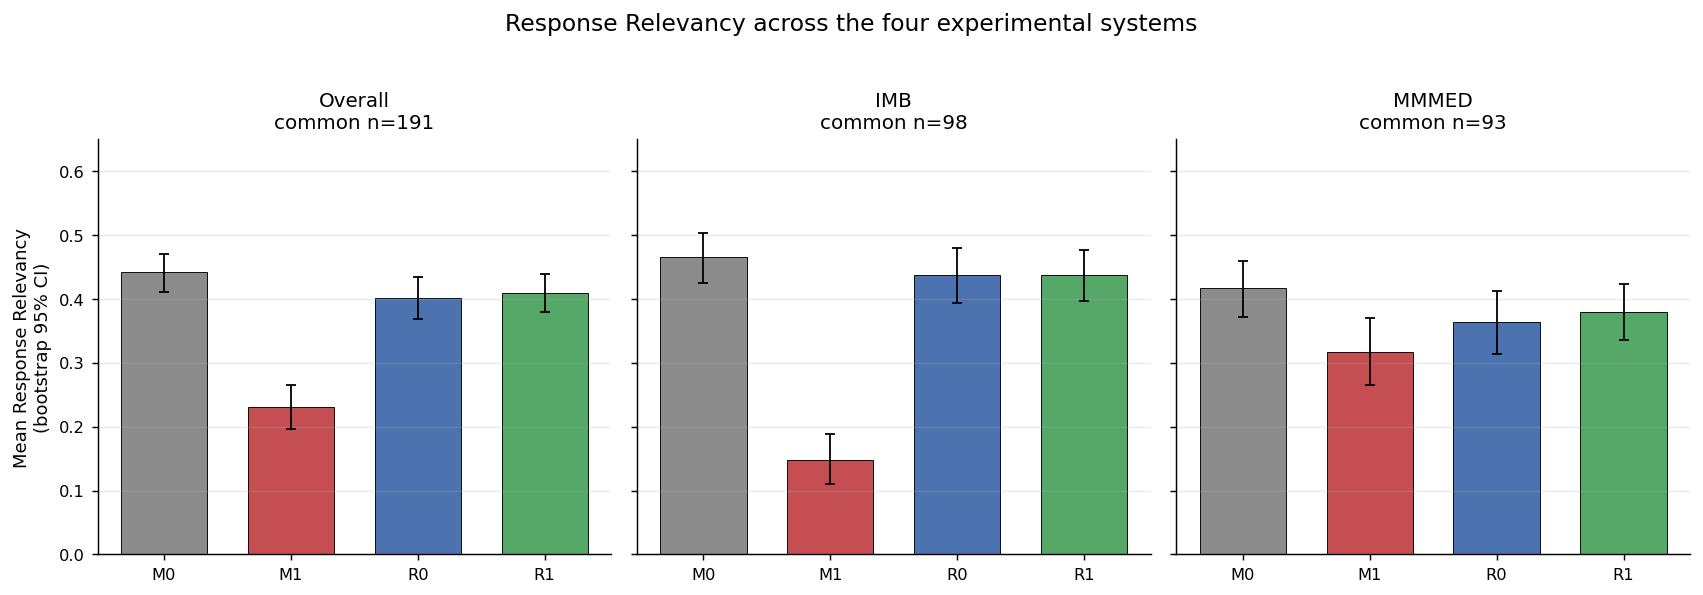

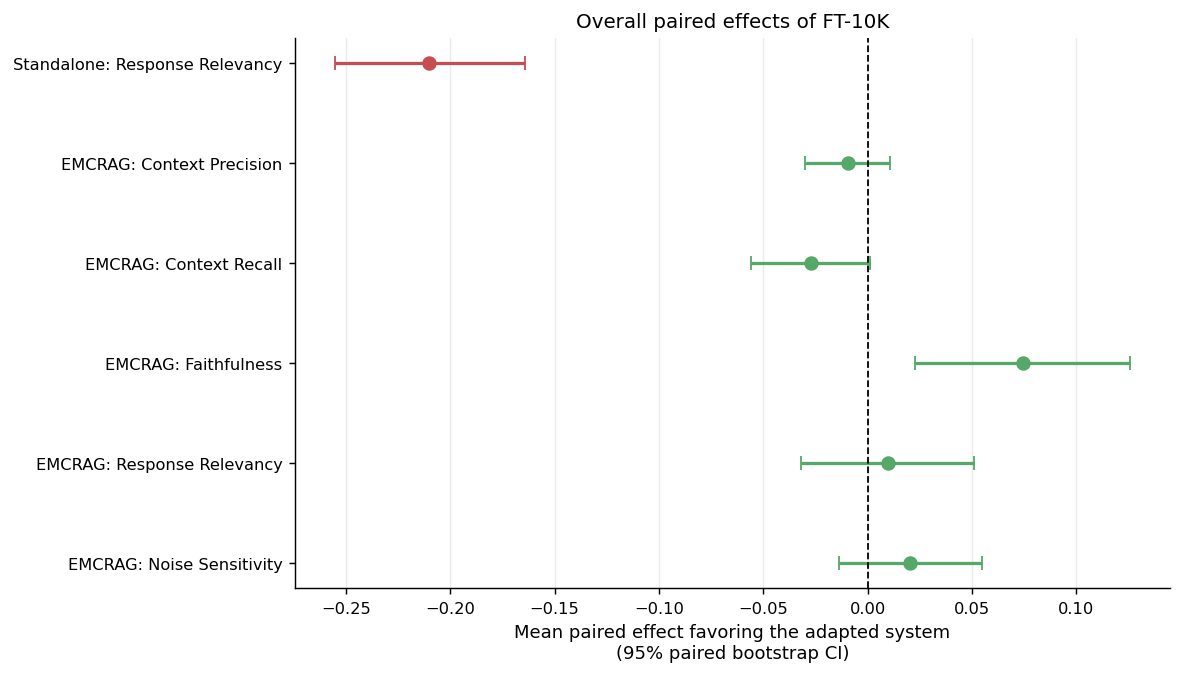

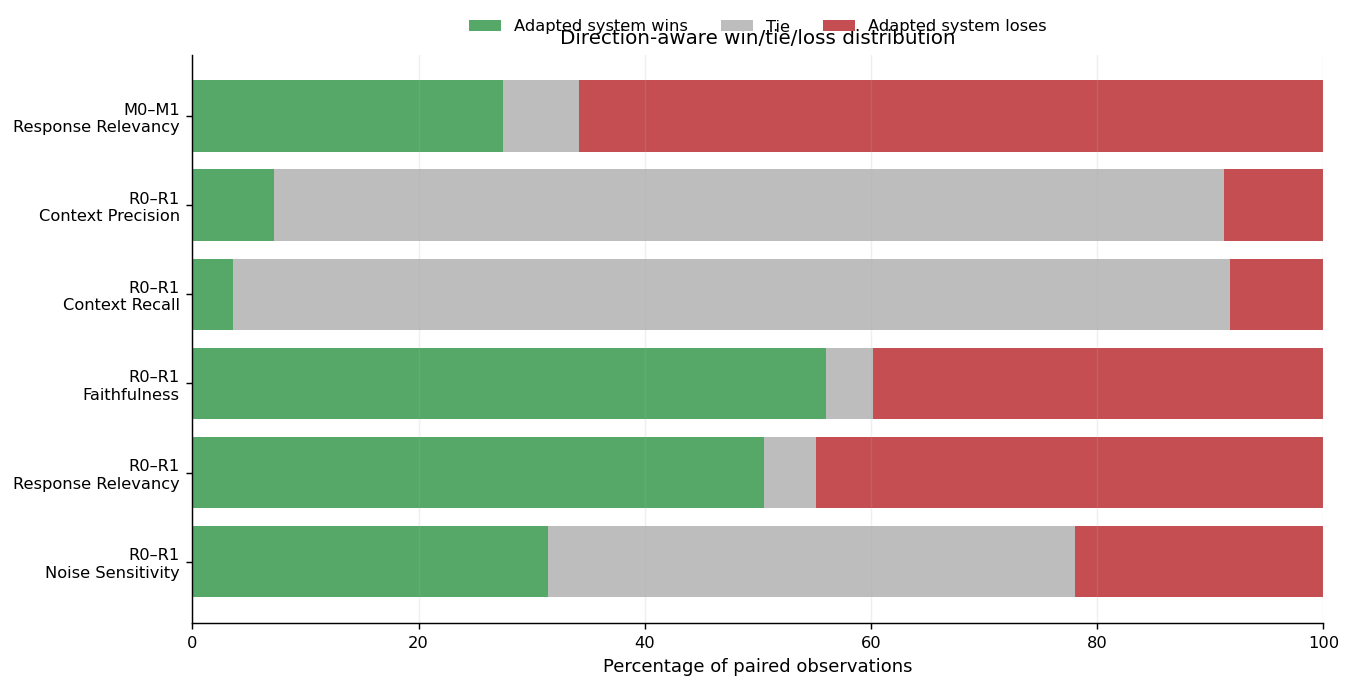

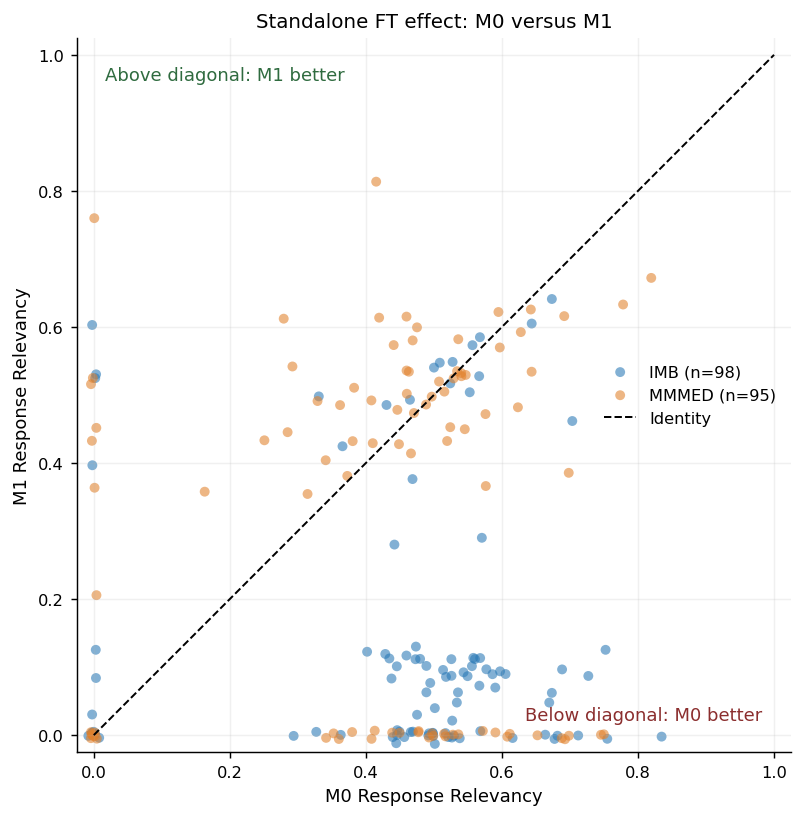

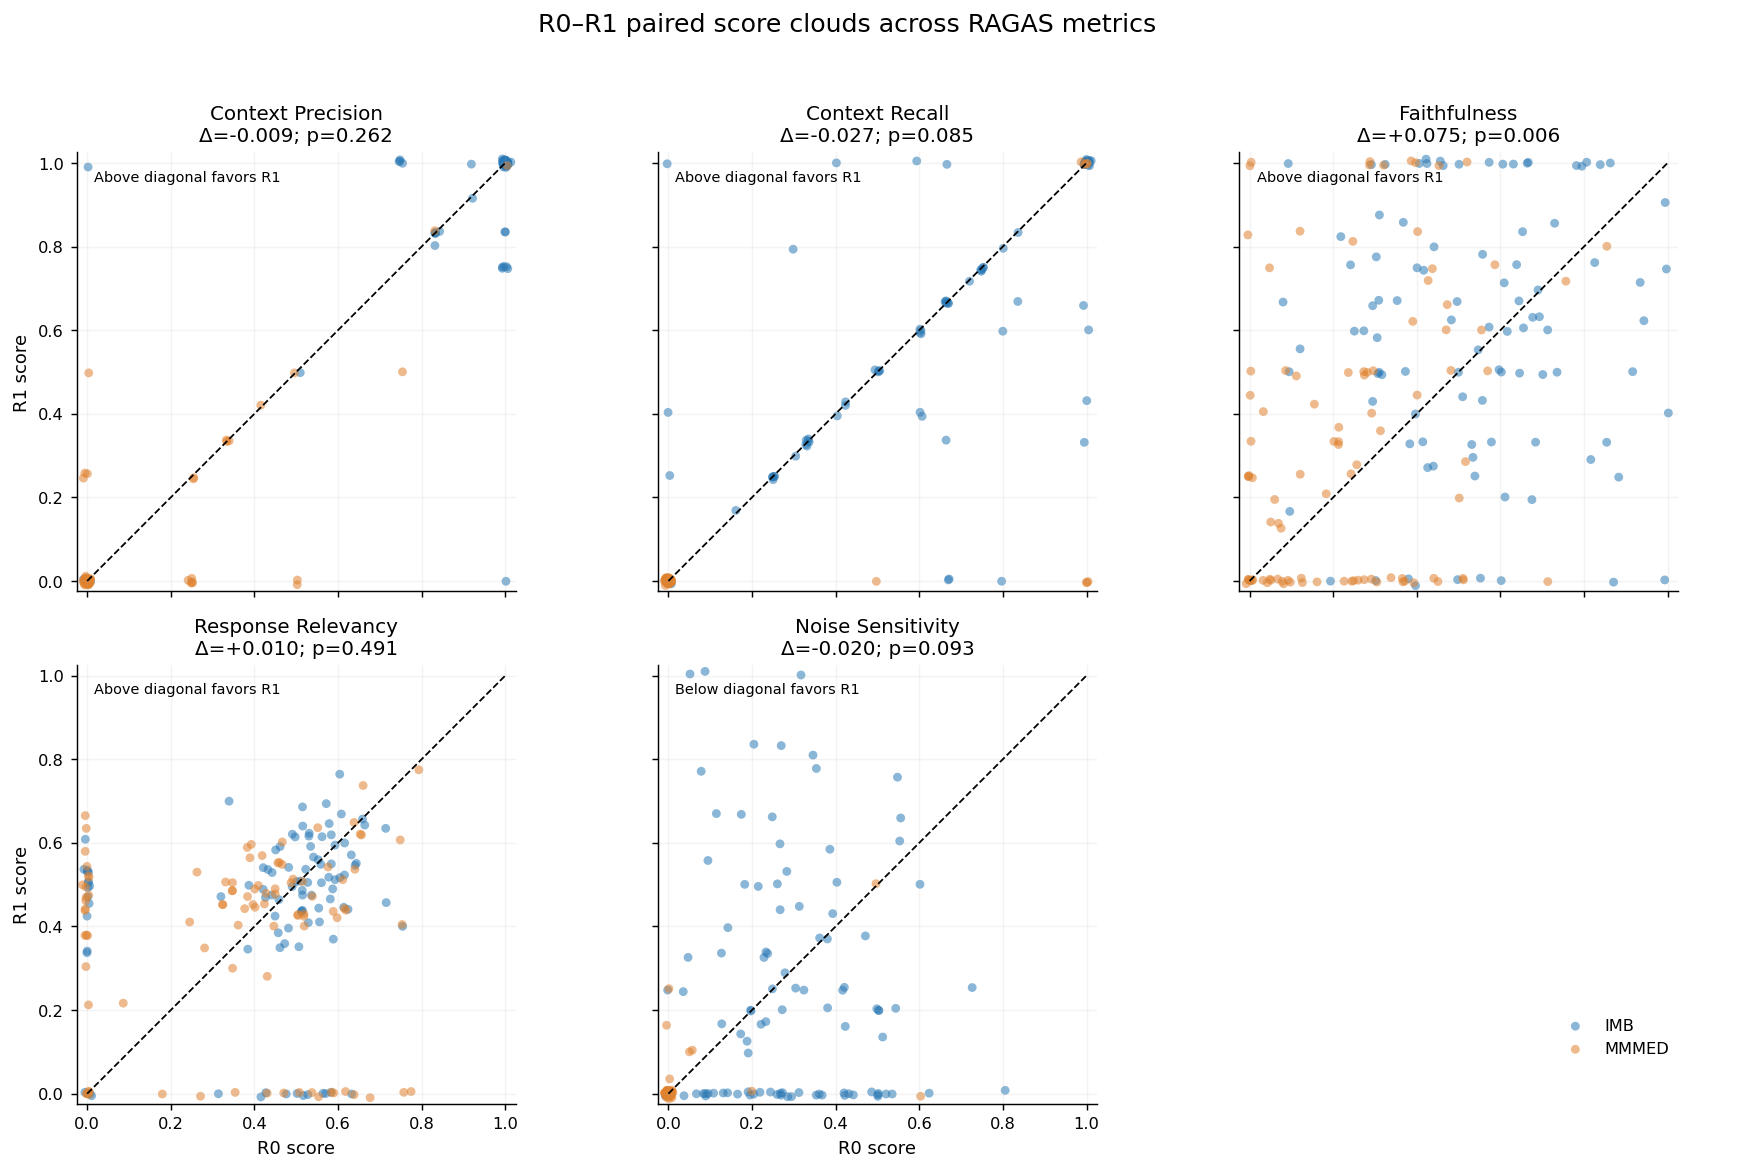

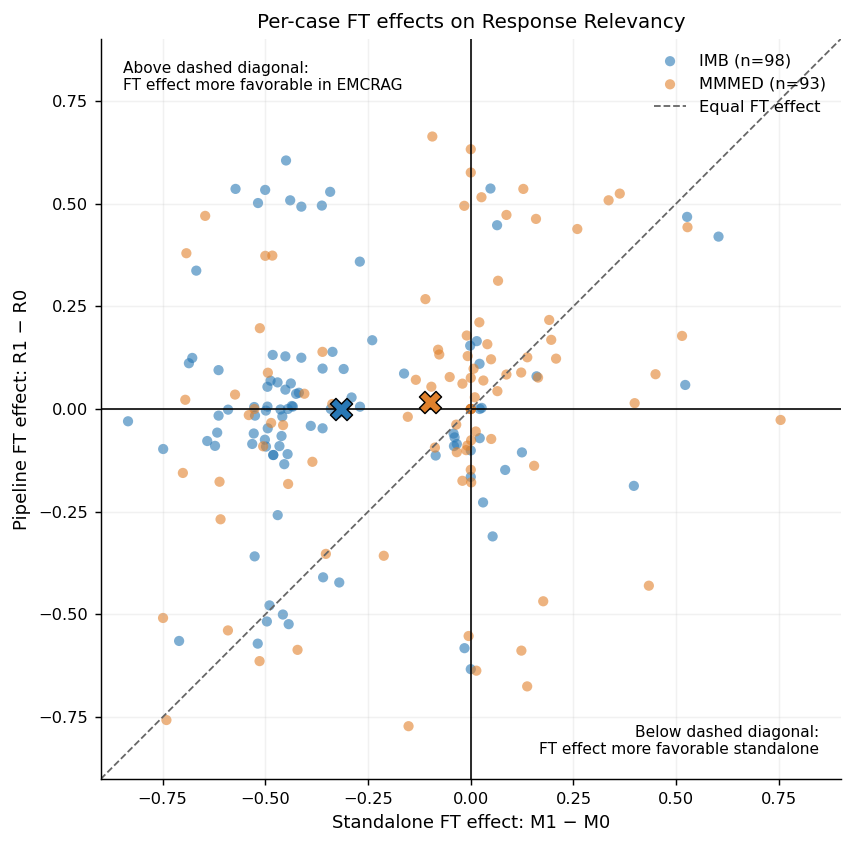

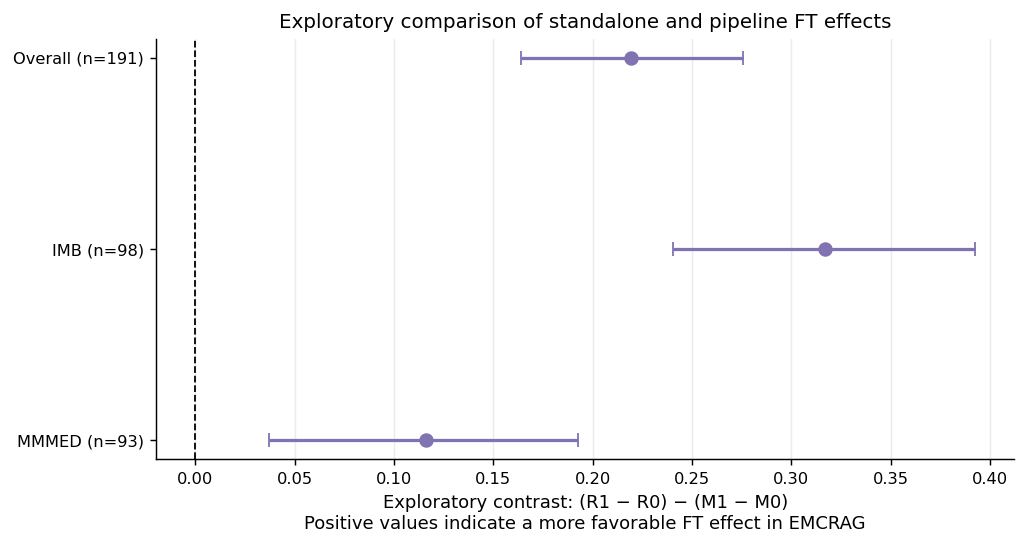


ANALISI INTEGRATA: PASS
M0–M1 paired: 193
R0–R1 Response Relevancy paired: 194
Coorte comune M0/M1/R0/R1: 191

TABELLA PRINCIPALE


,Comparison,Metric,Group,n,Before mean,After mean,Mean change [95% CI],Wilcoxon p,Matched rank-biserial,Win/Tie/Loss
0,Standalone FT effect,Response Relevancy,Overall,193,0.440699,0.230307,"-0.210 [-0.255, -0.164]",3.38e-13,-0.625537,53/13/127
1,Standalone FT effect,Response Relevancy,IMB,98,0.465266,0.148431,"-0.317 [-0.372, -0.258]",4.47e-12,-0.822172,16/4/78
2,Standalone FT effect,Response Relevancy,MMMED,95,0.415355,0.314769,"-0.101 [-0.165, -0.037]",0.018,-0.293237,37/9/49
3,EMCRAG FT effect,Context Precision,Overall,194,0.509021,0.499857,"-0.009 [-0.030, 0.011]",0.262,-0.229839,14/163/17
4,EMCRAG FT effect,Context Precision,IMB,100,0.915000,0.909722,"-0.005 [-0.037, 0.027]",0.729,-0.089474,10/81/9
5,EMCRAG FT effect,Context Precision,MMMED,94,0.077128,0.063830,"-0.013 [-0.037, 0.011]",0.303,-0.371795,4/82/8
6,EMCRAG FT effect,Context Recall,Overall,194,0.343152,0.316237,"-0.027 [-0.056, 0.001]",0.085,-0.409420,7/171/16
7,EMCRAG FT effect,Context Recall,IMB,100,0.590714,0.573500,"-0.017 [-0.061, 0.026]",0.481,-0.184211,7/81/12
8,EMCRAG FT effect,Context Recall,MMMED,94,0.079787,0.042553,"-0.037 [-0.074, -0.005]",0.125,-1.000000,0/90/4
9,EMCRAG FT effect,Faithfulness,Overall,191,0.390085,0.464833,"0.075 [0.023, 0.126]",0.006,0.233725,107/8/76



CONTRASTO ESPLORATIVO


,group,n_paired,mean_standalone_effect_M1_minus_M0,mean_pipeline_effect_R1_minus_R0,mean_contrast_pipeline_minus_standalone,bootstrap_95CI_low,bootstrap_95CI_high,wilcoxon_statistic,wilcoxon_p_two_sided,matched_rank_biserial
0,Overall,191,-0.210996,0.008175,0.219171,0.164125,0.275626,3803.0,2.845808e-11,0.562647
1,IMB_Curated_Test_Set_1000,98,-0.316835,0.000243,0.317079,0.240456,0.392454,641.0,4.245187e-10,0.730276
2,MMMED_Italian,93,-0.099466,0.016533,0.115999,0.036919,0.192619,1285.0,3.329913e-03,0.358302



Directory artefatti:
/home/eugrug/Project_CRAG_MedGemma/experimental_freeze_v07_06/paper_tables_figures

Manifest:
/home/eugrug/Project_CRAG_MedGemma/experimental_freeze_v07_06/paper_tables_figures/M0_M1_R0_R1_tables_figures_manifest.json
Manifest SHA256:
ed22d1ca889b1fa184ec80a78b1272d34622b919dc39559f245c644b7f87176c


In [11]:
# =============================================================================
# CONFRONTO INTEGRATO M0–M1 / R0–R1
# Tabelle, grafici a barre, forest plot e nuvole di dispersione per il paper
# =============================================================================

from pathlib import Path
import hashlib
import json
import math
import platform
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from scipy.stats import rankdata, wilcoxon


# -----------------------------------------------------------------------------
# 1. Configurazione
# -----------------------------------------------------------------------------

PROJECT_DIR = Path("/home/eugrug/Project_CRAG_MedGemma")

M0_M1_DIR = (
    PROJECT_DIR
    / "benchmark_m0_m1"
    / "ragas_m0_m1_v07_03"
)

R0_R1_DIR = (
    PROJECT_DIR
    / "benchmark_r0_r1"
    / "ragas_r1_v07_05"
    / "paired_analysis_r0_r1"
)

M0_M1_SUMMARY_PATH = (
    M0_M1_DIR
    / "response_relevancy_statistical_summary.csv"
)

M0_M1_PAIRED_PATH = (
    M0_M1_DIR
    / "response_relevancy_paired_differences.jsonl"
)

R0_R1_SUMMARY_PATH = (
    R0_R1_DIR
    / "R0_R1_statistical_summary.csv"
)

R0_R1_PAIRED_PATH = (
    R0_R1_DIR
    / "R0_R1_paired_differences.csv"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "experimental_freeze_v07_06"
    / "paper_tables_figures"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BOOTSTRAP_SEED = 20260831
BOOTSTRAP_RESAMPLES = 10_000
TIE_TOLERANCE = 1e-12

# Jitter usato esclusivamente per visualizzare punti sovrapposti.
SCATTER_JITTER_SD = 0.004
SCATTER_SEED = 20261006

GROUP_ORDER = [
    "Overall",
    "IMB_Curated_Test_Set_1000",
    "MMMED_Italian",
]

GROUP_LABELS = {
    "Overall": "Overall",
    "IMB_Curated_Test_Set_1000": "IMB",
    "MMMED_Italian": "MMMED",
}

METRIC_ORDER = [
    "context_precision",
    "context_recall",
    "faithfulness",
    "response_relevancy",
    "noise_sensitivity",
]

METRIC_LABELS = {
    "context_precision": "Context\nPrecision",
    "context_recall": "Context\nRecall",
    "faithfulness": "Faithfulness",
    "response_relevancy": "Response\nRelevancy",
    "noise_sensitivity": "Noise\nSensitivity",
}

DATASET_COLORS = {
    "IMB_Curated_Test_Set_1000": "#2878B5",
    "MMMED_Italian": "#E1812C",
}

SYSTEM_COLORS = {
    "M0": "#8C8C8C",
    "M1": "#C44E52",
    "R0": "#4C72B0",
    "R1": "#55A868",
}

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


# -----------------------------------------------------------------------------
# 2. Funzioni di utilità
# -----------------------------------------------------------------------------

def require(condition, message):
    if not condition:
        raise RuntimeError(message)


def sha256_file(path):
    path = Path(path)
    h = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)

    return h.hexdigest()


def read_jsonl_dataframe(path):
    rows = []

    for line_number, line in enumerate(
        Path(path).read_text(encoding="utf-8").splitlines(),
        start=1,
    ):
        if not line.strip():
            continue

        try:
            rows.append(json.loads(line))
        except json.JSONDecodeError as exc:
            raise RuntimeError(
                f"JSON non valido in {path}, riga {line_number}"
            ) from exc

    return pd.DataFrame(rows)


def find_column(df, candidates, description):
    for column in candidates:
        if column in df.columns:
            return column

    raise RuntimeError(
        f"Colonna non trovata per {description}. "
        f"Candidati: {candidates}. "
        f"Colonne disponibili: {list(df.columns)}"
    )


def get_first_value(row, candidates, default=None):
    for column in candidates:
        if column in row.index and pd.notna(row[column]):
            return row[column]

    return default


def bootstrap_mean_ci(values, seed, resamples=BOOTSTRAP_RESAMPLES):
    values = np.asarray(values, dtype=float)
    require(len(values) > 0, "Bootstrap richiesto su vettore vuoto")
    require(np.isfinite(values).all(), "Valori non finiti nel bootstrap")

    rng = np.random.default_rng(seed)

    bootstrap_means = np.empty(resamples, dtype=float)

    for index in range(resamples):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True,
        )
        bootstrap_means[index] = sample.mean()

    low, high = np.quantile(
        bootstrap_means,
        [0.025, 0.975],
    )

    return float(low), float(high)


def bootstrap_system_mean_ci(values, seed):
    return bootstrap_mean_ci(
        values=values,
        seed=seed,
        resamples=BOOTSTRAP_RESAMPLES,
    )


def save_figure(fig, basename):
    png_path = OUTPUT_DIR / f"{basename}.png"
    pdf_path = OUTPUT_DIR / f"{basename}.pdf"

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()
    plt.close(fig)

    return png_path, pdf_path


def deterministic_jitter(values, rng):
    values = np.asarray(values, dtype=float)

    jittered = values + rng.normal(
        loc=0.0,
        scale=SCATTER_JITTER_SD,
        size=len(values),
    )

    return np.clip(jittered, -0.015, 1.015)


def format_p_value(value):
    value = float(value)

    if value < 0.001:
        return f"{value:.2e}"

    return f"{value:.3f}"


def group_subset(df, group):
    if group == "Overall":
        return df.copy()

    return df.loc[df["dataset"] == group].copy()


def compute_paired_summary(
    values_before,
    values_after,
    higher_is_better=True,
):
    before = np.asarray(values_before, dtype=float)
    after = np.asarray(values_after, dtype=float)

    require(
        len(before) == len(after),
        "Vettori paired con lunghezze diverse",
    )
    require(
        len(before) > 0,
        "Nessuna osservazione paired",
    )
    require(
        np.isfinite(before).all() and np.isfinite(after).all(),
        "Valori non finiti nel confronto paired",
    )

    raw_delta = after - before

    favorable_delta = (
        raw_delta
        if higher_is_better
        else -raw_delta
    )

    nonzero = favorable_delta[
        np.abs(favorable_delta) > TIE_TOLERANCE
    ]

    if len(nonzero) > 0:
        wilcoxon_result = wilcoxon(
            nonzero,
            zero_method="wilcox",
            alternative="two-sided",
            method="auto",
        )

        ranks = rankdata(
            np.abs(nonzero),
            method="average",
        )

        w_plus = float(ranks[nonzero > 0].sum())
        w_minus = float(ranks[nonzero < 0].sum())

        rank_biserial = (
            (w_plus - w_minus)
            / (w_plus + w_minus)
        )

        wilcoxon_statistic = float(
            wilcoxon_result.statistic
        )

        wilcoxon_p = float(
            wilcoxon_result.pvalue
        )

    else:
        wilcoxon_statistic = math.nan
        wilcoxon_p = math.nan
        rank_biserial = 0.0

    return {
        "n_paired": int(len(raw_delta)),
        "before_mean": float(before.mean()),
        "after_mean": float(after.mean()),
        "mean_raw_delta": float(raw_delta.mean()),
        "median_raw_delta": float(np.median(raw_delta)),
        "wilcoxon_statistic": wilcoxon_statistic,
        "wilcoxon_p_two_sided": wilcoxon_p,
        "matched_rank_biserial_favoring_after": float(
            rank_biserial
        ),
        "after_wins_direction_aware": int(
            (favorable_delta > TIE_TOLERANCE).sum()
        ),
        "ties": int(
            (
                np.abs(favorable_delta)
                <= TIE_TOLERANCE
            ).sum()
        ),
        "after_losses_direction_aware": int(
            (favorable_delta < -TIE_TOLERANCE).sum()
        ),
    }


# -----------------------------------------------------------------------------
# 3. Gate sugli artefatti
# -----------------------------------------------------------------------------

required_paths = [
    M0_M1_SUMMARY_PATH,
    M0_M1_PAIRED_PATH,
    R0_R1_SUMMARY_PATH,
    R0_R1_PAIRED_PATH,
]

for path in required_paths:
    require(
        path.is_file(),
        f"Artefatto mancante: {path}",
    )

input_hashes = {
    str(path): sha256_file(path)
    for path in required_paths
}

print("INPUT GATE: PASS")

for path, digest in input_hashes.items():
    print(Path(path).name, digest)


# -----------------------------------------------------------------------------
# 4. Caricamento dati M0–M1
# -----------------------------------------------------------------------------

m0_m1_summary_raw = pd.read_csv(
    M0_M1_SUMMARY_PATH
)

m0_m1_paired_raw = read_jsonl_dataframe(
    M0_M1_PAIRED_PATH
)

m0_col = find_column(
    m0_m1_paired_raw,
    [
        "M0_response_relevancy",
        "M0_score",
        "M0",
    ],
    "score M0",
)

m1_col = find_column(
    m0_m1_paired_raw,
    [
        "M1_response_relevancy",
        "M1_score",
        "M1",
    ],
    "score M1",
)

m0_m1_paired = pd.DataFrame({
    "sample_id": m0_m1_paired_raw["sample_id"],
    "dataset": m0_m1_paired_raw["dataset"],
    "M0": pd.to_numeric(
        m0_m1_paired_raw[m0_col],
        errors="coerce",
    ),
    "M1": pd.to_numeric(
        m0_m1_paired_raw[m1_col],
        errors="coerce",
    ),
})

m0_m1_paired = m0_m1_paired.dropna(
    subset=["M0", "M1"]
).copy()

m0_m1_paired["delta_M1_minus_M0"] = (
    m0_m1_paired["M1"]
    - m0_m1_paired["M0"]
)

require(
    m0_m1_paired["sample_id"].duplicated().sum() == 0,
    "Sample duplicati nei dati M0–M1",
)


# -----------------------------------------------------------------------------
# 5. Caricamento dati R0–R1
# -----------------------------------------------------------------------------

r0_r1_summary_raw = pd.read_csv(
    R0_R1_SUMMARY_PATH
)

r0_r1_paired_raw = pd.read_csv(
    R0_R1_PAIRED_PATH
)

metric_col = find_column(
    r0_r1_paired_raw,
    ["metric", "metric_name"],
    "nome metrica R0–R1",
)

r0_col = find_column(
    r0_r1_paired_raw,
    ["R0_score", "R0", "score_R0"],
    "score R0",
)

r1_col = find_column(
    r0_r1_paired_raw,
    ["R1_score", "R1", "score_R1"],
    "score R1",
)

r0_r1_paired = pd.DataFrame({
    "sample_id": r0_r1_paired_raw["sample_id"],
    "dataset": r0_r1_paired_raw["dataset"],
    "metric": r0_r1_paired_raw[metric_col],
    "R0": pd.to_numeric(
        r0_r1_paired_raw[r0_col],
        errors="coerce",
    ),
    "R1": pd.to_numeric(
        r0_r1_paired_raw[r1_col],
        errors="coerce",
    ),
})

r0_r1_paired = r0_r1_paired.dropna(
    subset=["R0", "R1"]
).copy()

r0_r1_paired["delta_R1_minus_R0"] = (
    r0_r1_paired["R1"]
    - r0_r1_paired["R0"]
)

require(
    set(r0_r1_paired["metric"].unique())
    == set(METRIC_ORDER),
    "Set di metriche R0–R1 inatteso",
)

require(
    r0_r1_paired[
        ["sample_id", "metric"]
    ].duplicated().sum() == 0,
    "Combinazioni sample_id/metrica duplicate in R0–R1",
)


# -----------------------------------------------------------------------------
# 6. Normalizzazione delle summary statistiche
# -----------------------------------------------------------------------------

def normalize_m0_m1_summary(df):
    rows = []

    for _, row in df.iterrows():
        group = str(
            get_first_value(
                row,
                ["group", "dataset"],
                "Overall",
            )
        )

        rows.append({
            "comparison": "M0–M1",
            "metric": "response_relevancy",
            "group": group,
            "n_paired": int(
                get_first_value(
                    row,
                    ["n_paired", "n_pairs"],
                )
            ),
            "before_mean": float(
                get_first_value(
                    row,
                    ["M0_mean"],
                )
            ),
            "after_mean": float(
                get_first_value(
                    row,
                    ["M1_mean"],
                )
            ),
            "mean_raw_delta": float(
                get_first_value(
                    row,
                    [
                        "mean_delta_M1_minus_M0",
                        "mean_delta",
                    ],
                )
            ),
            "bootstrap_95CI_low": float(
                get_first_value(
                    row,
                    [
                        "bootstrap_95CI_low",
                        "bootstrap_ci_low",
                    ],
                )
            ),
            "bootstrap_95CI_high": float(
                get_first_value(
                    row,
                    [
                        "bootstrap_95CI_high",
                        "bootstrap_ci_high",
                    ],
                )
            ),
            "wilcoxon_p_two_sided": float(
                get_first_value(
                    row,
                    ["wilcoxon_p_two_sided"],
                )
            ),
            "matched_rank_biserial_favoring_after": float(
                get_first_value(
                    row,
                    [
                        "matched_rank_biserial",
                        "paired_rank_biserial_correlation",
                    ],
                )
            ),
            "after_wins_direction_aware": int(
                get_first_value(
                    row,
                    ["M1_wins", "wins_M1"],
                )
            ),
            "ties": int(
                get_first_value(
                    row,
                    ["ties"],
                )
            ),
            "after_losses_direction_aware": int(
                get_first_value(
                    row,
                    ["M1_losses", "losses_M1"],
                )
            ),
        })

    return pd.DataFrame(rows)


def normalize_r0_r1_summary(df):
    rows = []

    for _, row in df.iterrows():
        rows.append({
            "comparison": "R0–R1",
            "metric": str(row["metric"]),
            "group": str(row["group"]),
            "n_paired": int(row["n_paired"]),
            "before_mean": float(row["R0_mean"]),
            "after_mean": float(row["R1_mean"]),
            "mean_raw_delta": float(
                row["mean_delta_R1_minus_R0"]
            ),
            "bootstrap_95CI_low": float(
                row["bootstrap_95CI_low"]
            ),
            "bootstrap_95CI_high": float(
                row["bootstrap_95CI_high"]
            ),
            "wilcoxon_p_two_sided": float(
                row["wilcoxon_p_two_sided"]
            ),
            "matched_rank_biserial_favoring_after": float(
                row[
                    "matched_rank_biserial_favoring_R1"
                ]
            ),
            "after_wins_direction_aware": int(
                row["R1_wins_direction_aware"]
            ),
            "ties": int(row["ties"]),
            "after_losses_direction_aware": int(
                row["R1_losses_direction_aware"]
            ),
        })

    return pd.DataFrame(rows)


m0_m1_summary = normalize_m0_m1_summary(
    m0_m1_summary_raw
)

r0_r1_summary = normalize_r0_r1_summary(
    r0_r1_summary_raw
)

combined_summary = pd.concat(
    [m0_m1_summary, r0_r1_summary],
    ignore_index=True,
)

combined_summary_path = (
    OUTPUT_DIR
    / "Table_integrated_M0_M1_R0_R1_summary.csv"
)

combined_summary.to_csv(
    combined_summary_path,
    index=False,
)


# -----------------------------------------------------------------------------
# 7. Intersezione dei quattro sistemi per Response Relevancy
# -----------------------------------------------------------------------------

r0_r1_relevancy = r0_r1_paired.loc[
    r0_r1_paired["metric"]
    == "response_relevancy",
    [
        "sample_id",
        "dataset",
        "R0",
        "R1",
        "delta_R1_minus_R0",
    ],
].copy()

four_system_df = m0_m1_paired.merge(
    r0_r1_relevancy,
    on="sample_id",
    how="inner",
    suffixes=("_standalone", "_pipeline"),
)

require(
    (
        four_system_df["dataset_standalone"]
        == four_system_df["dataset_pipeline"]
    ).all(),
    "Dataset non concordanti nell’intersezione dei quattro sistemi",
)

four_system_df["dataset"] = (
    four_system_df["dataset_standalone"]
)

four_system_df = four_system_df[
    [
        "sample_id",
        "dataset",
        "M0",
        "M1",
        "R0",
        "R1",
        "delta_M1_minus_M0",
        "delta_R1_minus_R0",
    ]
].copy()

four_system_df[
    "contrast_pipeline_minus_standalone"
] = (
    four_system_df["delta_R1_minus_R0"]
    - four_system_df["delta_M1_minus_M0"]
)

four_system_path = (
    OUTPUT_DIR
    / "Table_four_system_response_relevancy_common_cases.csv"
)

four_system_df.to_csv(
    four_system_path,
    index=False,
)


# -----------------------------------------------------------------------------
# 8. Tabella delle medie M0, M1, R0 e R1 sulla coorte comune
# -----------------------------------------------------------------------------

four_system_mean_rows = []

for group_index, group in enumerate(GROUP_ORDER):
    subset = group_subset(
        four_system_df,
        group,
    )

    for system_index, system in enumerate(
        ["M0", "M1", "R0", "R1"]
    ):
        values = subset[system].to_numpy(dtype=float)

        ci_low, ci_high = bootstrap_system_mean_ci(
            values,
            seed=(
                BOOTSTRAP_SEED
                + 100 * group_index
                + system_index
            ),
        )

        four_system_mean_rows.append({
            "group": group,
            "system": system,
            "n": int(len(values)),
            "mean_response_relevancy": float(
                values.mean()
            ),
            "bootstrap_95CI_low": ci_low,
            "bootstrap_95CI_high": ci_high,
        })

four_system_means = pd.DataFrame(
    four_system_mean_rows
)

four_system_means_path = (
    OUTPUT_DIR
    / "Table_four_system_response_relevancy_means.csv"
)

four_system_means.to_csv(
    four_system_means_path,
    index=False,
)


# -----------------------------------------------------------------------------
# 9. Contrasto esplorativo degli effetti
#    (R1 − R0) − (M1 − M0)
# -----------------------------------------------------------------------------

interaction_rows = []

for group_index, group in enumerate(GROUP_ORDER):
    subset = group_subset(
        four_system_df,
        group,
    )

    contrast = subset[
        "contrast_pipeline_minus_standalone"
    ].to_numpy(dtype=float)

    ci_low, ci_high = bootstrap_mean_ci(
        contrast,
        seed=BOOTSTRAP_SEED + 1000 + group_index,
    )

    nonzero = contrast[
        np.abs(contrast) > TIE_TOLERANCE
    ]

    if len(nonzero) > 0:
        test = wilcoxon(
            nonzero,
            zero_method="wilcox",
            alternative="two-sided",
            method="auto",
        )

        ranks = rankdata(
            np.abs(nonzero),
            method="average",
        )

        w_plus = float(
            ranks[nonzero > 0].sum()
        )
        w_minus = float(
            ranks[nonzero < 0].sum()
        )

        rank_biserial = (
            (w_plus - w_minus)
            / (w_plus + w_minus)
        )

        statistic = float(test.statistic)
        p_value = float(test.pvalue)

    else:
        statistic = math.nan
        p_value = math.nan
        rank_biserial = 0.0

    interaction_rows.append({
        "group": group,
        "n_paired": int(len(contrast)),
        "mean_standalone_effect_M1_minus_M0": float(
            subset["delta_M1_minus_M0"].mean()
        ),
        "mean_pipeline_effect_R1_minus_R0": float(
            subset["delta_R1_minus_R0"].mean()
        ),
        "mean_contrast_pipeline_minus_standalone": float(
            contrast.mean()
        ),
        "bootstrap_95CI_low": ci_low,
        "bootstrap_95CI_high": ci_high,
        "wilcoxon_statistic": statistic,
        "wilcoxon_p_two_sided": p_value,
        "matched_rank_biserial": float(
            rank_biserial
        ),
    })

interaction_summary = pd.DataFrame(
    interaction_rows
)

interaction_summary_path = (
    OUTPUT_DIR
    / "Table_exploratory_effect_contrast.csv"
)

interaction_summary.to_csv(
    interaction_summary_path,
    index=False,
)


# -----------------------------------------------------------------------------
# 10. Tabella compatta pronta per il paper
# -----------------------------------------------------------------------------

paper_table = combined_summary.copy()

paper_table["comparison_label"] = paper_table[
    "comparison"
].map({
    "M0–M1": "Standalone FT effect",
    "R0–R1": "EMCRAG FT effect",
})

paper_table["metric_label"] = paper_table[
    "metric"
].map({
    key: label.replace("\n", " ")
    for key, label in METRIC_LABELS.items()
})

paper_table["group_label"] = paper_table[
    "group"
].map(GROUP_LABELS)

paper_table["mean_change_95CI"] = paper_table.apply(
    lambda row: (
        f"{row['mean_raw_delta']:.3f} "
        f"[{row['bootstrap_95CI_low']:.3f}, "
        f"{row['bootstrap_95CI_high']:.3f}]"
    ),
    axis=1,
)

paper_table["p_value"] = paper_table[
    "wilcoxon_p_two_sided"
].map(format_p_value)

paper_table["win_tie_loss"] = paper_table.apply(
    lambda row: (
        f"{int(row['after_wins_direction_aware'])}/"
        f"{int(row['ties'])}/"
        f"{int(row['after_losses_direction_aware'])}"
    ),
    axis=1,
)

paper_table = paper_table[
    [
        "comparison_label",
        "metric_label",
        "group_label",
        "n_paired",
        "before_mean",
        "after_mean",
        "mean_change_95CI",
        "p_value",
        "matched_rank_biserial_favoring_after",
        "win_tie_loss",
    ]
].rename(columns={
    "comparison_label": "Comparison",
    "metric_label": "Metric",
    "group_label": "Group",
    "n_paired": "n",
    "before_mean": "Before mean",
    "after_mean": "After mean",
    "mean_change_95CI": "Mean change [95% CI]",
    "p_value": "Wilcoxon p",
    "matched_rank_biserial_favoring_after":
        "Matched rank-biserial",
    "win_tie_loss": "Win/Tie/Loss",
})

paper_table_path = (
    OUTPUT_DIR
    / "Table_paper_ready_integrated_results.csv"
)

paper_table.to_csv(
    paper_table_path,
    index=False,
)

paper_table_latex_path = (
    OUTPUT_DIR
    / "Table_paper_ready_integrated_results.tex"
)

paper_table_latex_path.write_text(
    paper_table.to_latex(
        index=False,
        float_format="%.3f",
        escape=True,
    ),
    encoding="utf-8",
)


# -----------------------------------------------------------------------------
# 11. FIGURA 1
#     Barre: Response Relevancy nei quattro sistemi
# -----------------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(13.2, 4.4),
    sharey=True,
)

for ax, group in zip(axes, GROUP_ORDER):
    plot_df = four_system_means.loc[
        four_system_means["group"] == group
    ].copy()

    plot_df["system"] = pd.Categorical(
        plot_df["system"],
        categories=["M0", "M1", "R0", "R1"],
        ordered=True,
    )

    plot_df = plot_df.sort_values("system")

    x = np.arange(len(plot_df))

    means = plot_df[
        "mean_response_relevancy"
    ].to_numpy()

    lower_error = (
        means
        - plot_df["bootstrap_95CI_low"].to_numpy()
    )

    upper_error = (
        plot_df["bootstrap_95CI_high"].to_numpy()
        - means
    )

    ax.bar(
        x,
        means,
        color=[
            SYSTEM_COLORS[system]
            for system in plot_df["system"].astype(str)
        ],
        width=0.68,
        edgecolor="black",
        linewidth=0.5,
        yerr=np.vstack(
            [lower_error, upper_error]
        ),
        capsize=3,
        error_kw={
            "elinewidth": 1.0,
            "capthick": 1.0,
        },
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        plot_df["system"].astype(str)
    )

    ax.set_title(
        f"{GROUP_LABELS[group]}\n"
        f"common n={plot_df['n'].iloc[0]}"
    )

    ax.set_ylim(0.0, 0.65)
    ax.grid(
        axis="y",
        alpha=0.25,
    )

axes[0].set_ylabel(
    "Mean Response Relevancy\n(bootstrap 95% CI)"
)

fig.suptitle(
    "Response Relevancy across the four experimental systems",
    fontsize=13,
    y=1.03,
)

fig.tight_layout()

figure_1_paths = save_figure(
    fig,
    "Figure_1_four_system_response_relevancy_bars",
)


# -----------------------------------------------------------------------------
# 12. FIGURA 2
#     Forest plot degli effetti paired complessivi
# -----------------------------------------------------------------------------

overall_effects = combined_summary.loc[
    combined_summary["group"] == "Overall"
].copy()

effect_rows = []

standalone_row = overall_effects.loc[
    overall_effects["comparison"] == "M0–M1"
].iloc[0]

effect_rows.append({
    "label": "Standalone: Response Relevancy",
    "effect": standalone_row["mean_raw_delta"],
    "ci_low": standalone_row["bootstrap_95CI_low"],
    "ci_high": standalone_row["bootstrap_95CI_high"],
    "color": SYSTEM_COLORS["M1"],
})

for metric in METRIC_ORDER:
    row = overall_effects.loc[
        (
            overall_effects["comparison"]
            == "R0–R1"
        )
        & (
            overall_effects["metric"]
            == metric
        )
    ].iloc[0]

    # Noise Sensitivity viene invertita soltanto nella figura
    # per rendere tutti gli effetti orientati nello stesso senso:
    # valori positivi = vantaggio del sistema adattato.
    if metric == "noise_sensitivity":
        effect = -float(row["mean_raw_delta"])
        ci_low = -float(
            row["bootstrap_95CI_high"]
        )
        ci_high = -float(
            row["bootstrap_95CI_low"]
        )
    else:
        effect = float(row["mean_raw_delta"])
        ci_low = float(row["bootstrap_95CI_low"])
        ci_high = float(row["bootstrap_95CI_high"])

    effect_rows.append({
        "label": (
            "EMCRAG: "
            + METRIC_LABELS[metric].replace("\n", " ")
        ),
        "effect": effect,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "color": SYSTEM_COLORS["R1"],
    })

effect_df = pd.DataFrame(effect_rows)

fig, ax = plt.subplots(
    figsize=(9.2, 5.3)
)

y = np.arange(len(effect_df))[::-1]

for position, (_, row) in zip(
    y,
    effect_df.iterrows(),
):
    ax.errorbar(
        row["effect"],
        position,
        xerr=np.array([[
            row["effect"] - row["ci_low"],
            row["ci_high"] - row["effect"],
        ]]).T,
        fmt="o",
        color=row["color"],
        ecolor=row["color"],
        capsize=4,
        markersize=7,
        linewidth=1.8,
    )

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
)

ax.set_yticks(y)
ax.set_yticklabels(effect_df["label"])

ax.set_xlabel(
    "Mean paired effect favoring the adapted system\n"
    "(95% paired bootstrap CI)"
)

ax.set_title(
    "Overall paired effects of FT-10K"
)

ax.grid(
    axis="x",
    alpha=0.25,
)

fig.tight_layout()

figure_2_paths = save_figure(
    fig,
    "Figure_2_overall_paired_effects_forest",
)


# -----------------------------------------------------------------------------
# 13. FIGURA 3
#     Barre percentuali Win / Tie / Loss
# -----------------------------------------------------------------------------

wtl_rows = []

for _, row in overall_effects.iterrows():
    if row["comparison"] == "M0–M1":
        label = "M0–M1\nResponse Relevancy"
    else:
        label = (
            "R0–R1\n"
            + METRIC_LABELS[
                row["metric"]
            ].replace("\n", " ")
        )

    total = (
        row["after_wins_direction_aware"]
        + row["ties"]
        + row["after_losses_direction_aware"]
    )

    wtl_rows.append({
        "label": label,
        "win": (
            100
            * row["after_wins_direction_aware"]
            / total
        ),
        "tie": 100 * row["ties"] / total,
        "loss": (
            100
            * row["after_losses_direction_aware"]
            / total
        ),
    })

wtl_df = pd.DataFrame(wtl_rows)

fig, ax = plt.subplots(
    figsize=(10.5, 5.4)
)

y = np.arange(len(wtl_df))

ax.barh(
    y,
    wtl_df["win"],
    color="#55A868",
    label="Adapted system wins",
)

ax.barh(
    y,
    wtl_df["tie"],
    left=wtl_df["win"],
    color="#BDBDBD",
    label="Tie",
)

ax.barh(
    y,
    wtl_df["loss"],
    left=wtl_df["win"] + wtl_df["tie"],
    color="#C44E52",
    label="Adapted system loses",
)

ax.set_yticks(y)
ax.set_yticklabels(wtl_df["label"])
ax.invert_yaxis()

ax.set_xlim(0, 100)
ax.set_xlabel(
    "Percentage of paired observations"
)

ax.set_title(
    "Direction-aware win/tie/loss distribution"
)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=3,
    frameon=False,
)

ax.grid(
    axis="x",
    alpha=0.2,
)

fig.tight_layout()

figure_3_paths = save_figure(
    fig,
    "Figure_3_overall_win_tie_loss_bars",
)


# -----------------------------------------------------------------------------
# 14. FIGURA 4
#     Nuvola di dispersione M0 contro M1
# -----------------------------------------------------------------------------

rng = np.random.default_rng(
    SCATTER_SEED
)

fig, ax = plt.subplots(
    figsize=(6.8, 6.4)
)

for dataset in [
    "IMB_Curated_Test_Set_1000",
    "MMMED_Italian",
]:
    subset = m0_m1_paired.loc[
        m0_m1_paired["dataset"] == dataset
    ]

    x = deterministic_jitter(
        subset["M0"].to_numpy(dtype=float),
        rng,
    )

    y = deterministic_jitter(
        subset["M1"].to_numpy(dtype=float),
        rng,
    )

    ax.scatter(
        x,
        y,
        s=30,
        alpha=0.58,
        color=DATASET_COLORS[dataset],
        label=(
            f"{GROUP_LABELS[dataset]} "
            f"(n={len(subset)})"
        ),
        edgecolors="none",
        rasterized=True,
    )

ax.plot(
    [0, 1],
    [0, 1],
    color="black",
    linestyle="--",
    linewidth=1.1,
    label="Identity",
)

ax.set_xlim(-0.025, 1.025)
ax.set_ylim(-0.025, 1.025)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    "M0 Response Relevancy"
)

ax.set_ylabel(
    "M1 Response Relevancy"
)

ax.set_title(
    "Standalone FT effect: M0 versus M1"
)

ax.text(
    0.04,
    0.96,
    "Above diagonal: M1 better",
    transform=ax.transAxes,
    va="top",
    color="#2F6B3F",
)

ax.text(
    0.96,
    0.04,
    "Below diagonal: M0 better",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    color="#8B2E2E",
)

ax.grid(alpha=0.18)
ax.legend(frameon=False)

fig.tight_layout()

figure_4_paths = save_figure(
    fig,
    "Figure_4_scatter_cloud_M0_vs_M1",
)


# -----------------------------------------------------------------------------
# 15. FIGURA 5
#     Nuvole di dispersione R0 contro R1 per tutte le metriche
# -----------------------------------------------------------------------------

rng = np.random.default_rng(
    SCATTER_SEED + 1
)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(14.0, 9.0),
    sharex=True,
    sharey=True,
)

axes_flat = axes.flatten()

for metric_index, metric in enumerate(METRIC_ORDER):
    ax = axes_flat[metric_index]

    metric_df = r0_r1_paired.loc[
        r0_r1_paired["metric"] == metric
    ].copy()

    for dataset in [
        "IMB_Curated_Test_Set_1000",
        "MMMED_Italian",
    ]:
        subset = metric_df.loc[
            metric_df["dataset"] == dataset
        ]

        x = deterministic_jitter(
            subset["R0"].to_numpy(dtype=float),
            rng,
        )

        y = deterministic_jitter(
            subset["R1"].to_numpy(dtype=float),
            rng,
        )

        ax.scatter(
            x,
            y,
            s=24,
            alpha=0.54,
            color=DATASET_COLORS[dataset],
            label=GROUP_LABELS[dataset],
            edgecolors="none",
            rasterized=True,
        )

    ax.plot(
        [0, 1],
        [0, 1],
        color="black",
        linestyle="--",
        linewidth=1.0,
    )

    overall_row = r0_r1_summary.loc[
        (
            r0_r1_summary["group"]
            == "Overall"
        )
        & (
            r0_r1_summary["metric"]
            == metric
        )
    ].iloc[0]

    ax.set_title(
        f"{METRIC_LABELS[metric].replace(chr(10), ' ')}\n"
        f"Δ={overall_row['mean_raw_delta']:+.3f}; "
        f"p={format_p_value(overall_row['wilcoxon_p_two_sided'])}"
    )

    ax.set_xlim(-0.025, 1.025)
    ax.set_ylim(-0.025, 1.025)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.15)

    if metric == "noise_sensitivity":
        interpretation = "Below diagonal favors R1"
    else:
        interpretation = "Above diagonal favors R1"

    ax.text(
        0.04,
        0.96,
        interpretation,
        transform=ax.transAxes,
        va="top",
        fontsize=8,
    )

axes_flat[-1].axis("off")

for ax in axes[:, 0]:
    ax.set_ylabel("R1 score")

for ax in axes[1, :]:
    ax.set_xlabel("R0 score")

handles, labels = axes_flat[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower right",
    bbox_to_anchor=(0.96, 0.09),
    frameon=False,
)

fig.suptitle(
    "R0–R1 paired score clouds across RAGAS metrics",
    fontsize=14,
    y=0.995,
)

fig.tight_layout(
    rect=[0, 0, 1, 0.97]
)

figure_5_paths = save_figure(
    fig,
    "Figure_5_scatter_clouds_R0_vs_R1_all_metrics",
)


# -----------------------------------------------------------------------------
# 16. FIGURA 6
#     Dispersione degli effetti individuali:
#     x = M1−M0, y = R1−R0
# -----------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7.2, 6.6)
)

for dataset in [
    "IMB_Curated_Test_Set_1000",
    "MMMED_Italian",
]:
    subset = four_system_df.loc[
        four_system_df["dataset"] == dataset
    ]

    ax.scatter(
        subset["delta_M1_minus_M0"],
        subset["delta_R1_minus_R0"],
        s=32,
        alpha=0.60,
        color=DATASET_COLORS[dataset],
        label=(
            f"{GROUP_LABELS[dataset]} "
            f"(n={len(subset)})"
        ),
        edgecolors="none",
        rasterized=True,
    )

    ax.scatter(
        subset["delta_M1_minus_M0"].mean(),
        subset["delta_R1_minus_R0"].mean(),
        s=150,
        marker="X",
        color=DATASET_COLORS[dataset],
        edgecolor="black",
        linewidth=0.8,
        zorder=5,
    )

combined_limits = np.concatenate([
    four_system_df[
        "delta_M1_minus_M0"
    ].to_numpy(dtype=float),
    four_system_df[
        "delta_R1_minus_R0"
    ].to_numpy(dtype=float),
])

limit = max(
    0.2,
    float(np.max(np.abs(combined_limits))) * 1.08,
)

ax.axhline(
    0,
    color="black",
    linewidth=0.9,
)

ax.axvline(
    0,
    color="black",
    linewidth=0.9,
)

ax.plot(
    [-limit, limit],
    [-limit, limit],
    color="#666666",
    linestyle="--",
    linewidth=1.0,
    label="Equal FT effect",
)

ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    "Standalone FT effect: M1 − M0"
)

ax.set_ylabel(
    "Pipeline FT effect: R1 − R0"
)

ax.set_title(
    "Per-case FT effects on Response Relevancy"
)

ax.text(
    0.03,
    0.97,
    "Above dashed diagonal:\nFT effect more favorable in EMCRAG",
    transform=ax.transAxes,
    va="top",
    fontsize=8.5,
)

ax.text(
    0.97,
    0.03,
    "Below dashed diagonal:\nFT effect more favorable standalone",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=8.5,
)

ax.grid(alpha=0.17)
ax.legend(frameon=False)

fig.tight_layout()

figure_6_paths = save_figure(
    fig,
    "Figure_6_scatter_standalone_vs_pipeline_effects",
)


# -----------------------------------------------------------------------------
# 17. FIGURA 7
#     Forest plot del contrasto esplorativo
# -----------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.0, 4.3)
)

plot_interaction = interaction_summary.copy()

plot_interaction["group"] = pd.Categorical(
    plot_interaction["group"],
    categories=GROUP_ORDER,
    ordered=True,
)

plot_interaction = plot_interaction.sort_values(
    "group"
)

y = np.arange(len(plot_interaction))[::-1]

for position, (_, row) in zip(
    y,
    plot_interaction.iterrows(),
):
    effect = row[
        "mean_contrast_pipeline_minus_standalone"
    ]

    ax.errorbar(
        effect,
        position,
        xerr=np.array([[
            effect - row["bootstrap_95CI_low"],
            row["bootstrap_95CI_high"] - effect,
        ]]).T,
        fmt="o",
        color="#8172B2",
        ecolor="#8172B2",
        capsize=4,
        markersize=7,
        linewidth=1.8,
    )

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
)

ax.set_yticks(y)

ax.set_yticklabels([
    (
        f"{GROUP_LABELS[row['group']]} "
        f"(n={int(row['n_paired'])})"
    )
    for _, row in plot_interaction.iterrows()
])

ax.set_xlabel(
    "Exploratory contrast: "
    "(R1 − R0) − (M1 − M0)\n"
    "Positive values indicate a more favorable FT effect in EMCRAG"
)

ax.set_title(
    "Exploratory comparison of standalone and pipeline FT effects"
)

ax.grid(
    axis="x",
    alpha=0.25,
)

fig.tight_layout()

figure_7_paths = save_figure(
    fig,
    "Figure_7_exploratory_effect_contrast_forest",
)


# -----------------------------------------------------------------------------
# 18. Salvataggio dei dati usati nelle nuvole di dispersione
# -----------------------------------------------------------------------------

m0_m1_scatter_path = (
    OUTPUT_DIR
    / "Figure_4_source_data_M0_M1.csv"
)

m0_m1_paired.to_csv(
    m0_m1_scatter_path,
    index=False,
)

r0_r1_scatter_path = (
    OUTPUT_DIR
    / "Figure_5_source_data_R0_R1.csv"
)

r0_r1_paired.to_csv(
    r0_r1_scatter_path,
    index=False,
)

effect_scatter_path = (
    OUTPUT_DIR
    / "Figure_6_source_data_effect_comparison.csv"
)

four_system_df.to_csv(
    effect_scatter_path,
    index=False,
)


# -----------------------------------------------------------------------------
# 19. README con interpretazione e didascalie
# -----------------------------------------------------------------------------

readme_path = (
    OUTPUT_DIR
    / "README_tables_figures.md"
)

readme_text = f"""# EMCRAG integrated M0–M1 and R0–R1 analysis

## Frozen inputs

- M0–M1 statistical summary: `{M0_M1_SUMMARY_PATH}`
- M0–M1 paired differences: `{M0_M1_PAIRED_PATH}`
- R0–R1 statistical summary: `{R0_R1_SUMMARY_PATH}`
- R0–R1 paired differences: `{R0_R1_PAIRED_PATH}`

## Cohorts

- M0–M1 paired observations: {len(m0_m1_paired)}
- R0–R1 Response Relevancy paired observations: {len(r0_r1_relevancy)}
- Four-system common Response Relevancy cohort: {len(four_system_df)}

## Figure captions

### Figure 1

Mean Response Relevancy for M0, M1, R0 and R1 on the common
four-system cohort. Error bars represent 95% non-parametric bootstrap
confidence intervals for the system-specific means.

### Figure 2

Overall paired effects of FT-10K. Points represent mean paired
differences and error bars represent 95% paired bootstrap confidence
intervals. Noise Sensitivity is sign-inverted in this figure only so
that positive values consistently indicate an advantage of the adapted
system.

### Figure 3

Direction-aware proportions of wins, ties and losses for the adapted
system. For Noise Sensitivity, lower values are treated as favorable.

### Figure 4

Paired scatter plot of standalone Response Relevancy scores for M0 and
M1. Points above the identity line favor M1; points below it favor M0.

### Figure 5

Paired R0–R1 scatter plots for the five RAGAS metrics. Points above the
identity line favor R1 for Context Precision, Context Recall,
Faithfulness and Response Relevancy. For Noise Sensitivity, points
below the identity line favor R1.

### Figure 6

Per-case comparison of the FT effect on Response Relevancy. The
horizontal axis represents M1−M0 and the vertical axis represents
R1−R0. Points above the dashed identity line indicate that the FT effect
was more favorable inside EMCRAG than in the standalone setting.
Crosses represent dataset-specific mean effects.

### Figure 7

Exploratory contrast between the pipeline and standalone FT effects:
(R1−R0)−(M1−M0). Positive values indicate that the effect was more
favorable inside EMCRAG. This analysis is post hoc and should be
reported as exploratory.

## Scatter-plot jitter

A deterministic Gaussian jitter with standard deviation
{SCATTER_JITTER_SD} was used only to reveal overlapping observations.
All statistical analyses and exported source-data tables retain the
original exact scores.

## Statistical interpretation

The confirmatory analyses remain the separately prespecified paired
comparisons M0–M1 and R0–R1. The four-system common-cohort comparison
and the interaction contrast are descriptive or exploratory and should
not be presented as independently prespecified confirmatory tests.
"""

readme_path.write_text(
    readme_text,
    encoding="utf-8",
)


# -----------------------------------------------------------------------------
# 20. Manifest finale degli artefatti
# -----------------------------------------------------------------------------

artifact_paths = [
    combined_summary_path,
    four_system_path,
    four_system_means_path,
    interaction_summary_path,
    paper_table_path,
    paper_table_latex_path,
    m0_m1_scatter_path,
    r0_r1_scatter_path,
    effect_scatter_path,
    readme_path,
    *figure_1_paths,
    *figure_2_paths,
    *figure_3_paths,
    *figure_4_paths,
    *figure_5_paths,
    *figure_6_paths,
    *figure_7_paths,
]

manifest = {
    "status": "PASS",
    "analysis": "Integrated M0-M1 and R0-R1 paper analysis",
    "created_with": {
        "python": sys.version,
        "platform": platform.platform(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "matplotlib": matplotlib.__version__,
    },
    "bootstrap_seed": BOOTSTRAP_SEED,
    "bootstrap_resamples": BOOTSTRAP_RESAMPLES,
    "scatter_seed": SCATTER_SEED,
    "scatter_jitter_sd_display_only": SCATTER_JITTER_SD,
    "input_files": [
        {
            "path": str(path),
            "sha256": input_hashes[str(path)],
        }
        for path in required_paths
    ],
    "cohorts": {
        "M0_M1_paired": int(len(m0_m1_paired)),
        "R0_R1_response_relevancy_paired": int(
            len(r0_r1_relevancy)
        ),
        "four_system_common": int(
            len(four_system_df)
        ),
    },
    "artifacts": [],
}

for path in artifact_paths:
    require(
        Path(path).is_file(),
        f"Artefatto non creato: {path}",
    )

    manifest["artifacts"].append({
        "path": str(path),
        "sha256": sha256_file(path),
        "size_bytes": Path(path).stat().st_size,
    })

manifest_path = (
    OUTPUT_DIR
    / "M0_M1_R0_R1_tables_figures_manifest.json"
)

manifest_path.write_text(
    json.dumps(
        manifest,
        ensure_ascii=False,
        indent=2,
        sort_keys=True,
    )
    + "\n",
    encoding="utf-8",
)

manifest_sha256 = sha256_file(
    manifest_path
)


# -----------------------------------------------------------------------------
# 21. Output finale
# -----------------------------------------------------------------------------

print("\nANALISI INTEGRATA: PASS")
print("M0–M1 paired:", len(m0_m1_paired))
print(
    "R0–R1 Response Relevancy paired:",
    len(r0_r1_relevancy),
)
print(
    "Coorte comune M0/M1/R0/R1:",
    len(four_system_df),
)

print("\nTABELLA PRINCIPALE")
display(paper_table)

print("\nCONTRASTO ESPLORATIVO")
display(interaction_summary)

print("\nDirectory artefatti:")
print(OUTPUT_DIR)

print("\nManifest:")
print(manifest_path)

print("Manifest SHA256:")
print(manifest_sha256)

## Interpretazione scientifica integrata dei grafici M0–M1 e R0–R1

Le figure riassumono due esperimenti paired distinti: l’effetto del fine-tuning FT-10K su MedGemma standalone (**M0→M1**) e l’effetto dello stesso adapter quando viene applicato esclusivamente al nodo generatore finale della pipeline EMCRAG congelata (**R0→R1**).

### Risultato standalone

Il confronto M0–M1 mostra una riduzione marcata della Response Relevancy dopo il fine-tuning. La media passa da 0,4407 a 0,2303, con una differenza paired media di −0,2104, IC bootstrap 95% [−0,2554; −0,1644] e test di Wilcoxon \(p=3,38\times10^{-13}\). L’effetto negativo è particolarmente ampio nel sottogruppo IMB, ma rimane presente anche in MMMED.

Il FT-10K non ha quindi migliorato il modello standalone. Il risultato riguarda questa specifica configurazione QLoRA, il relativo dataset e l’obiettivo di addestramento e non dimostra l’inefficacia generale del supervised fine-tuning.

### Risultato nella pipeline EMCRAG

Nel confronto R0–R1, la Faithfulness aumenta da 0,3901 a 0,4648, con differenza paired media di +0,0747, IC bootstrap 95% [+0,0229; +0,1259] e \(p=0,0061\). Si tratta dell’unico miglioramento chiaramente supportato dai risultati complessivi.

Non emergono invece variazioni statisticamente supportate per:

- Context Precision: Δ=−0,0092;
- Context Recall: Δ=−0,0269;
- Response Relevancy: Δ=+0,0100;
- Noise Sensitivity: Δ=−0,0205, dove valori inferiori sono preferibili.

Pertanto R1 non rappresenta un miglioramento generale di EMCRAG. Il risultato positivo è circoscritto alla maggiore fedeltà delle risposte rispetto al contesto recuperato.

### Lettura integrata delle figure selezionate

Il grafico a barre dei quattro sistemi evidenzia il forte peggioramento M0→M1 e la sostanziale stabilità R0→R1 nella Response Relevancy. Il forest plot conferma che l’unico effetto positivo con intervallo di confidenza interamente favorevole a R1 riguarda la Faithfulness.

La nuvola degli effetti individuali confronta, per ciascun caso, \(M1-M0\) sull’asse orizzontale e \(R1-R0\) sull’asse verticale. Molti casi mostrano un effetto standalone negativo, mentre gli effetti nella pipeline sono maggiormente distribuiti intorno allo zero. I punti sopra la diagonale indicano che l’effetto del fine-tuning è più favorevole all’interno di EMCRAG rispetto allo standalone.

Questa disposizione è compatibile con l’ipotesi che retrieval, routing correttivo e costruzione strutturata del contesto attenuino l’instabilità del generatore adattato. Non dimostra tuttavia un effetto causale protettivo della pipeline. Inoltre, un punto sopra la diagonale non rappresenta necessariamente un miglioramento assoluto di R1, ma può indicare soltanto un deterioramento meno pronunciato.

Il jitter applicato alle nuvole è esclusivamente grafico e deterministico: serve a rendere visibili gli score sovrapposti e non modifica i dati né le analisi statistiche.

### Conclusione sperimentale

L’ipotesi di miglioramento standalone non è supportata. L’ipotesi di miglioramento nella pipeline è supportata soltanto parzialmente: FT-10K aumenta la Faithfulness, mantiene sostanzialmente stabile la Response Relevancy e non produce cambiamenti statisticamente supportati nelle altre metriche.

Il risultato scientifico principale è quindi un beneficio selettivo di grounding nella pipeline correttiva, non un miglioramento generale del modello o della qualità clinica delle risposte. Il confronto congiunto degli effetti standalone e pipeline rimane esplorativo e deve essere presentato con questa qualificazione nel paper.